# Sales Forecasting & Demand Prediction Analysis

## 03 — Exploratory Data Analysis (EDA)

### Objectives
- Analyze overall sales trends.
- Identify seasonal and monthly demand patterns.
- Compare sales performance across stores.
- Identify high-demand and low-demand items.
- Explore weekly and weekend sales patterns.
- Generate business insights for demand forecasting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [2]:
df = pd.read_csv(
    "../data/processed/sales_cleaned.csv",
    parse_dates=["date"]
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (913000, 10)


,date,store,item,sales,Year,Month,Quarter,Day,Day_of_Week,Is_Weekend
0,2013-01-01,1,1,13,2013,1,1,1,1,0
1,2013-01-02,1,1,11,2013,1,1,2,2,0
2,2013-01-03,1,1,14,2013,1,1,3,3,0
3,2013-01-04,1,1,13,2013,1,1,4,4,0
4,2013-01-05,1,1,10,2013,1,1,5,5,1


In [3]:
print("========== EDA DATASET VERIFICATION ==========")

print("Total Records:", len(df))
print("Total Columns:", df.shape[1])

print("Date Range:", df["date"].min(), "to", df["date"].max())

print("Unique Stores:", df["store"].nunique())
print("Unique Items:", df["item"].nunique())

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Business Keys:",
      df.duplicated(subset=["date", "store", "item"]).sum())

print("Total Units Sold:", df["sales"].sum())

print("========== VERIFICATION COMPLETE ==========")

========== EDA DATASET VERIFICATION ==========
Total Records: 913000
Total Columns: 10
Date Range: 2013-01-01 00:00:00 to 2017-12-31 00:00:00
Unique Stores: 10
Unique Items: 50
Missing Values: 0
Duplicate Business Keys: 0
Total Units Sold: 47704512
========== VERIFICATION COMPLETE ==========


## 1. Overall Sales Trend Analysis

### 1.1 Daily Sales Trend

Objective: Analyze daily unit sales across all stores and items to understand overall demand patterns.

In [5]:
# Aggregate total units sold by date
daily_sales = (
    df.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
    .rename(columns={"sales": "Total_Units_Sold"})
)

print("Daily Sales Dataset Shape:", daily_sales.shape)

print("\nFirst 5 Records:")
display(daily_sales.head())

print("\nLast 5 Records:")
display(daily_sales.tail())

Daily Sales Dataset Shape: (1826, 2)

First 5 Records:


,date,Total_Units_Sold
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237



Last 5 Records:


,date,Total_Units_Sold
1821,2017-12-27,20378
1822,2017-12-28,21885
1823,2017-12-29,23535
1824,2017-12-30,24988
1825,2017-12-31,26420


In [6]:
print("========== DAILY SALES VALIDATION ==========")

print("Total Days:", len(daily_sales))
print("First Date:", daily_sales["date"].min())
print("Last Date:", daily_sales["date"].max())

print("Total Units Sold:", daily_sales["Total_Units_Sold"].sum())

print("Average Daily Units Sold:",
      round(daily_sales["Total_Units_Sold"].mean(), 2))

print("Minimum Daily Units Sold:",
      daily_sales["Total_Units_Sold"].min())

print("Maximum Daily Units Sold:",
      daily_sales["Total_Units_Sold"].max())

print("Missing Values:",
      daily_sales.isnull().sum().sum())

print("Total Matches Original:",
      daily_sales["Total_Units_Sold"].sum() == df["sales"].sum())

print("========== VALIDATION COMPLETE ==========")

========== DAILY SALES VALIDATION ==========
Total Days: 1826
First Date: 2013-01-01 00:00:00
Last Date: 2017-12-31 00:00:00
Total Units Sold: 47704512
Average Daily Units Sold: 26125.14
Minimum Daily Units Sold: 11709
Maximum Daily Units Sold: 44936
Missing Values: 0
Total Matches Original: True
========== VALIDATION COMPLETE ==========


### 1.2 Daily Sales Trend Visualization

This visualization shows total daily units sold across all stores and items from January 2013 to December 2017.

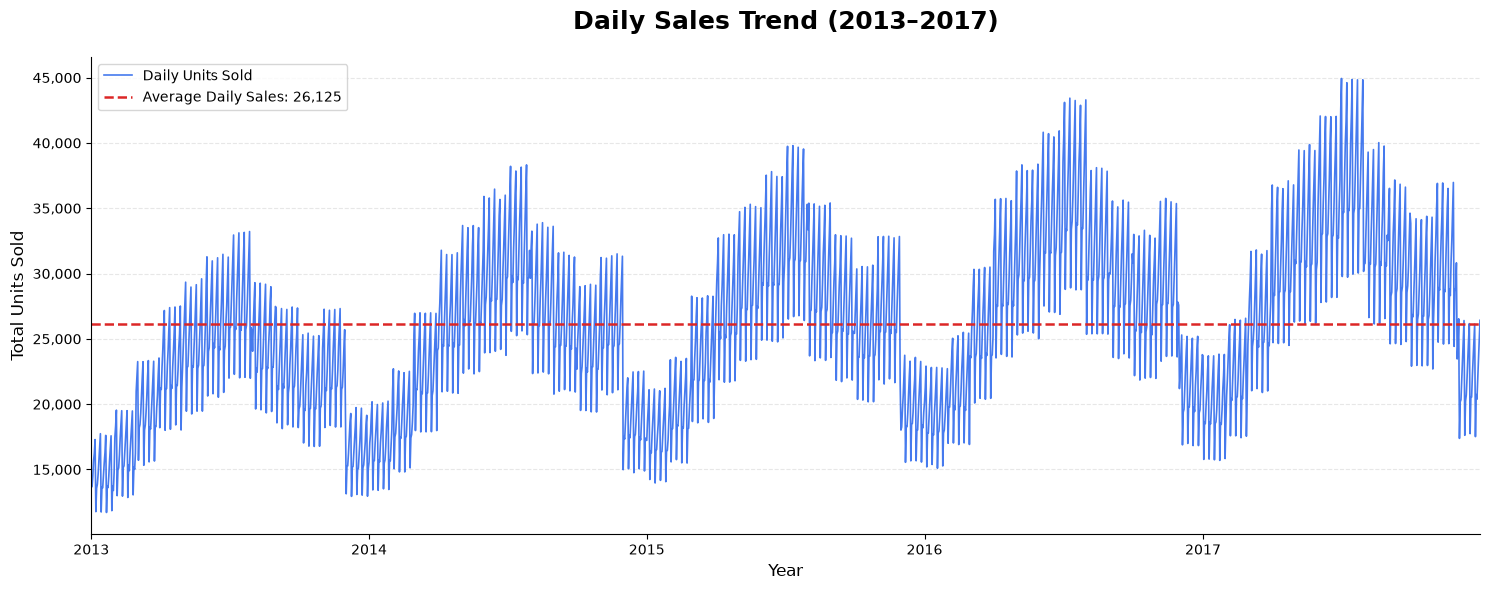

In [9]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Create figure
fig, ax = plt.subplots(figsize=(15, 6))

# Plot daily sales
ax.plot(
    daily_sales["date"],
    daily_sales["Total_Units_Sold"],
    color="#2563EB",
    linewidth=1.2,
    alpha=0.85,
    label="Daily Units Sold"
)

# Add average sales reference line
average_sales = daily_sales["Total_Units_Sold"].mean()

ax.axhline(
    y=average_sales,
    color="#DC2626",
    linestyle="--",
    linewidth=1.8,
    label=f"Average Daily Sales: {average_sales:,.0f}"
)

# Titles and labels
ax.set_title(
    "Daily Sales Trend (2013–2017)",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total Units Sold", fontsize=12)

# Display year labels
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Format sales values with commas
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Chart appearance
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper left", fontsize=10)

ax.set_xlim(
    daily_sales["date"].min(),
    daily_sales["date"].max()
)

plt.tight_layout()
plt.show()

In [10]:
# Save the chart for reports and portfolio documentation
fig.savefig(
    "../reports/figures/daily_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

print("Daily sales trend chart saved successfully!")

Daily sales trend chart saved successfully!


### 1.3 Business Insights — Daily Sales Trend

**Observation 1: Long-Term Demand Growth**

The daily sales trend suggests an overall increase in unit demand between 2013 and 2017. Despite daily fluctuations, later years generally exhibit higher sales levels than earlier years.

**Observation 2: Recurring Seasonal Demand**

The visualization shows repeated patterns of rising and falling demand across multiple years. This suggests the presence of seasonality, which should be investigated through monthly and weekly sales analysis.

**Observation 3: Significant Daily Sales Variation**

- Average daily units sold: **26,125.14**
- Minimum daily units sold: **11,709**
- Maximum daily units sold: **44,936**

The considerable difference between minimum and maximum daily demand highlights the importance of forecasting for inventory and operational planning.

**Business Implications**

- Use historical sales patterns to anticipate periods of high demand.
- Consider seasonal factors when designing forecasting models.
- Improve inventory planning by accounting for demand variability.
- Analyze individual stores and items to identify differences in demand behavior.

**Next Analysis:** Quantify yearly sales growth and investigate monthly demand patterns.

## 2. Yearly Sales Trend Analysis

### 2.1 Yearly Sales Aggregation and Growth

**Objective:** Calculate annual units sold and year-over-year growth to evaluate long-term demand trends from 2013 to 2017.

In [11]:
# Calculate total units sold for each year
yearly_sales = (
    df.groupby("Year", as_index=False)["sales"]
    .sum()
    .rename(columns={"sales": "Total_Units_Sold"})
    .sort_values("Year")
    .reset_index(drop=True)
)

print("Yearly Sales Dataset Shape:", yearly_sales.shape)

display(yearly_sales)

Yearly Sales Dataset Shape: (5, 2)


,Year,Total_Units_Sold
0,2013,7941243
1,2014,9135482
2,2015,9536887
3,2016,10357160
4,2017,10733740


In [12]:
# Calculate year-over-year growth percentage
yearly_sales["YoY_Growth_Percent"] = (
    yearly_sales["Total_Units_Sold"]
    .pct_change() * 100
)

print("========== YEARLY SALES AND GROWTH ==========")

display(
    yearly_sales.style.format({
        "Total_Units_Sold": "{:,.0f}",
        "YoY_Growth_Percent": "{:+.2f}%",
    }, na_rep="N/A")
)

========== YEARLY SALES AND GROWTH ==========


,Year,Total_Units_Sold,YoY_Growth_Percent
0,2013,"7,941,243",N/A
1,2014,"9,135,482",+15.04%
2,2015,"9,536,887",+4.39%
3,2016,"10,357,160",+8.60%
4,2017,"10,733,740",+3.64%


In [13]:
print("========== YEARLY SALES VALIDATION ==========")

print("Number of Years:", len(yearly_sales))

print("Total Units Sold:",
      yearly_sales["Total_Units_Sold"].sum())

print("Matches Original Dataset:",
      yearly_sales["Total_Units_Sold"].sum() == df["sales"].sum())

print("Year with Highest Sales:",
      yearly_sales.loc[
          yearly_sales["Total_Units_Sold"].idxmax(), "Year"
      ])

print("Year with Lowest Sales:",
      yearly_sales.loc[
          yearly_sales["Total_Units_Sold"].idxmin(), "Year"
      ])

print("Missing YoY Values:",
      yearly_sales["YoY_Growth_Percent"].isna().sum())

print("========== VALIDATION COMPLETE ==========")

========== YEARLY SALES VALIDATION ==========
Number of Years: 5
Total Units Sold: 47704512
Matches Original Dataset: True
Year with Highest Sales: 2017
Year with Lowest Sales: 2013
Missing YoY Values: 1
========== VALIDATION COMPLETE ==========


In [14]:
print("========== YEARLY SALES SUMMARY ==========")

print(
    yearly_sales.to_string(
        index=False,
        formatters={
            "Total_Units_Sold": "{:,.0f}".format,
            "YoY_Growth_Percent": lambda x: f"{x:+.2f}%"
        }
    )
)

========== YEARLY SALES SUMMARY ==========
 Year Total_Units_Sold YoY_Growth_Percent
 2013        7,941,243                NaN
 2014        9,135,482            +15.04%
 2015        9,536,887             +4.39%
 2016       10,357,160             +8.60%
 2017       10,733,740             +3.64%


### 2.2 Yearly Sales Growth Visualization

Objective: Visualize annual unit sales and year-over-year demand growth between 2013 and 2017.

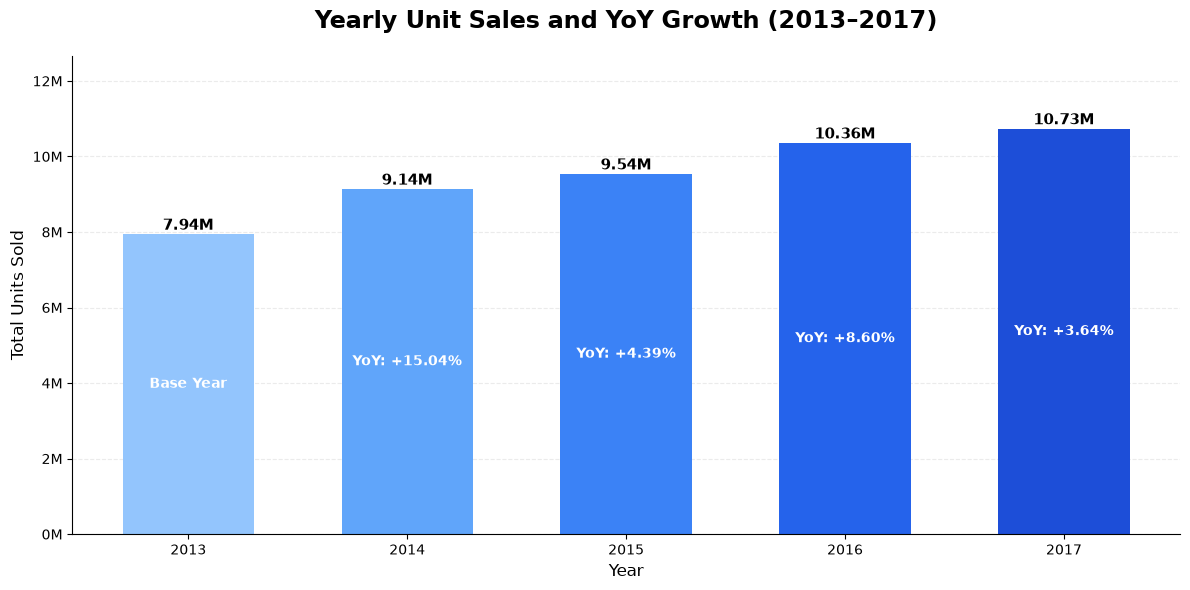

In [15]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 6))

years = yearly_sales["Year"].astype(str)
sales = yearly_sales["Total_Units_Sold"]
growth = yearly_sales["YoY_Growth_Percent"]

# Draw yearly sales bars
bars = ax.bar(
    years,
    sales,
    color=["#93C5FD", "#60A5FA", "#3B82F6",
           "#2563EB", "#1D4ED8"],
    width=0.6
)

# Add total sales labels above bars
for bar, value in zip(bars, sales):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 120000,
        f"{value / 1_000_000:.2f}M",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Add growth labels inside bars
for bar, yoy in zip(bars, growth):
    label = "Base Year" if pd.isna(yoy) else f"YoY: +{yoy:.2f}%"

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() * 0.50,
        label,
        ha="center",
        va="center",
        fontsize=10,
        color="white" if bar.get_height() > 0 else "black",
        fontweight="bold"
    )

# Title and axes
ax.set_title(
    "Yearly Unit Sales and YoY Growth (2013–2017)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total Units Sold", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.0f}M")
)

ax.set_ylim(0, sales.max() * 1.18)

# Improve appearance
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [16]:
fig.savefig(
    "../reports/figures/yearly_sales_growth.png",
    dpi=300,
    bbox_inches="tight"
)

print("Yearly sales growth chart saved successfully!")

Yearly sales growth chart saved successfully!


### 2.3 Business Insights — Yearly Sales Trend

**Observation 1: Consistent Annual Demand Growth**

Total annual units sold increased from **7,941,243 in 2013** to **10,733,740 in 2017**, representing approximately **35.17% overall growth**.

**Observation 2: Highest Year-over-Year Growth in 2014**

The largest annual growth rate occurred in **2014 (+15.04%)**, followed by 2016 (+8.60%), 2015 (+4.39%), and 2017 (+3.64%).

**Observation 3: Positive but Variable Growth**

Annual sales increased in every year of the dataset. However, growth rates were not constant, indicating that demand growth varied over time.

**Business Implications**

- Long-term inventory planning should account for increasing unit demand.
- Forecasting models should capture both trend and seasonal patterns.
- Store-level and item-level analysis is needed before making specific inventory allocation decisions.
- Historical growth rates should be used as context rather than assumed to continue unchanged.

**Next Analysis:** Examine monthly sales patterns to identify recurring seasonal demand.

## 3. Monthly Sales and Seasonality Analysis

### 3.1 Monthly Sales Aggregation

**Objective:** Analyze monthly unit sales to identify demand patterns and prepare for seasonality analysis.

In [17]:
# Aggregate sales by year and month
monthly_sales = (
    df.groupby(["Year", "Month"], as_index=False)["sales"]
    .sum()
    .rename(columns={"sales": "Total_Units_Sold"})
    .sort_values(["Year", "Month"])
    .reset_index(drop=True)
)

# Create a monthly date column
monthly_sales["Month_Date"] = pd.to_datetime(
    monthly_sales[["Year", "Month"]].assign(Day=1)
    .rename(columns={"Year": "year", "Month": "month", "Day": "day"})
)

print("Monthly Sales Dataset Shape:", monthly_sales.shape)

display(monthly_sales.head())
display(monthly_sales.tail())

Monthly Sales Dataset Shape: (60, 4)


,Year,Month,Total_Units_Sold,Month_Date
0,2013,1,454904,2013-01-01
1,2013,2,459417,2013-02-01
2,2013,3,617382,2013-03-01
3,2013,4,682274,2013-04-01
4,2013,5,763242,2013-05-01


,Year,Month,Total_Units_Sold,Month_Date
55,2017,8,1026403,2017-08-01
56,2017,9,935263,2017-09-01
57,2017,10,891160,2017-10-01
58,2017,11,928837,2017-11-01
59,2017,12,695170,2017-12-01


In [18]:
print("========== MONTHLY SALES VALIDATION ==========")

print("Total Months:", len(monthly_sales))

print("First Month:", monthly_sales["Month_Date"].min())
print("Last Month:", monthly_sales["Month_Date"].max())

print("Total Units Sold:",
      monthly_sales["Total_Units_Sold"].sum())

print("Matches Original Dataset:",
      monthly_sales["Total_Units_Sold"].sum() == df["sales"].sum())

print("Missing Values:",
      monthly_sales.isnull().sum().sum())

print("Highest Sales Month:")
display(
    monthly_sales.nlargest(1, "Total_Units_Sold")
)

print("Lowest Sales Month:")
display(
    monthly_sales.nsmallest(1, "Total_Units_Sold")
)

print("========== VALIDATION COMPLETE ==========")

========== MONTHLY SALES VALIDATION ==========
Total Months: 60
First Month: 2013-01-01 00:00:00
Last Month: 2017-12-01 00:00:00
Total Units Sold: 47704512
Matches Original Dataset: True
Missing Values: 0
Highest Sales Month:


,Year,Month,Total_Units_Sold,Month_Date
54,2017,7,1171393,2017-07-01


Lowest Sales Month:


,Year,Month,Total_Units_Sold,Month_Date
0,2013,1,454904,2013-01-01


========== VALIDATION COMPLETE ==========


### 3.2 Monthly Sales Trend Visualization

**Objective:** Visualize monthly units sold from January 2013 to December 2017 to identify long-term trends and recurring seasonal fluctuations.

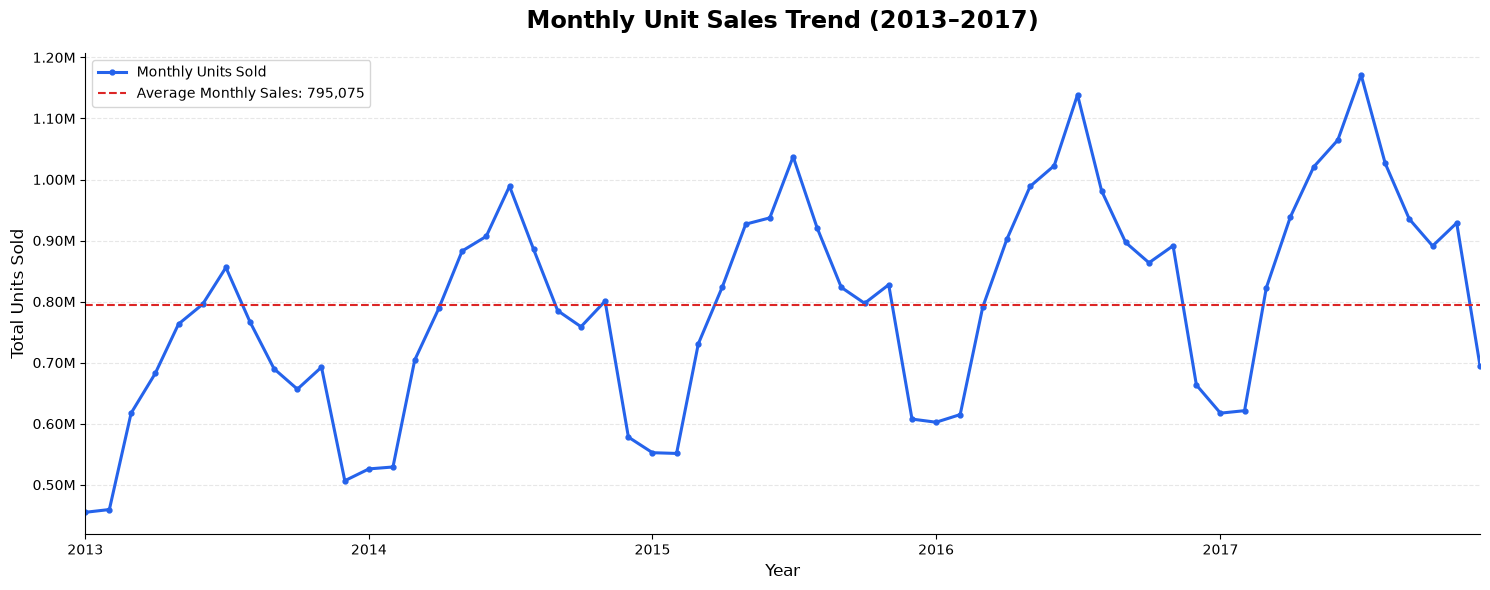

In [19]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(15, 6))

# Plot monthly unit sales
ax.plot(
    monthly_sales["Month_Date"],
    monthly_sales["Total_Units_Sold"],
    color="#2563EB",
    linewidth=2.2,
    marker="o",
    markersize=3.5,
    label="Monthly Units Sold"
)

# Add average monthly sales reference line
avg_monthly_sales = monthly_sales["Total_Units_Sold"].mean()

ax.axhline(
    avg_monthly_sales,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label=f"Average Monthly Sales: {avg_monthly_sales:,.0f}"
)

# Chart title and axis labels
ax.set_title(
    "Monthly Unit Sales Trend (2013–2017)",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total Units Sold", fontsize=12)

# Display year labels
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Limit X-axis to actual dataset period
ax.set_xlim(
    monthly_sales["Month_Date"].min(),
    monthly_sales["Month_Date"].max()
)

# Format Y-axis values
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.2f}M")
)

# Improve appearance
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

In [20]:
fig.savefig(
    "../reports/figures/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

print("Monthly sales trend chart saved successfully!")

Monthly sales trend chart saved successfully!


### 3.3 Business Insights — Monthly Sales Trend

**Observation 1: Increasing Monthly Demand**

Monthly unit sales generally increased between 2013 and 2017, supporting the positive long-term growth identified in the yearly analysis.

**Observation 2: Recurring Seasonal Patterns**

Monthly sales show repeated increases toward the middle of each year, followed by declines around the beginning of the following year. This suggests annual seasonality in customer demand.

**Observation 3: Highest and Lowest Monthly Sales**

- Highest recorded month: **July 2017 — 1,171,393 units**
- Lowest recorded month: **January 2013 — 454,904 units**
- Average monthly demand: **795,075 units**

**Business Implications**

- Consider seasonal demand patterns when planning inventory replenishment.
- Prepare for potentially higher demand during mid-year periods.
- Incorporate annual seasonality into future forecasting models.
- Investigate individual stores and items before applying the same seasonal assumptions to every product.

**Next Analysis:** Compare average monthly demand across calendar months to quantify seasonality.

### 3.4 Month-of-Year Seasonality Analysis

Objective: Identify recurring high-demand and low-demand months by comparing average monthly unit sales across 2013–2017.

In [22]:
import calendar

# Average monthly demand across five years
seasonal_sales = (
    monthly_sales.groupby("Month", as_index=False)["Total_Units_Sold"]
    .mean()
    .rename(columns={"Total_Units_Sold": "Average_Monthly_Units"})
    .sort_values("Month")
    .reset_index(drop=True)
)

# Convert month numbers into names without date parsing
seasonal_sales["Month_Name"] = seasonal_sales["Month"].map(
    lambda month: calendar.month_name[month]
)

print("Seasonality Dataset Shape:", seasonal_sales.shape)

display(seasonal_sales)

Seasonality Dataset Shape: (12, 3)


,Month,Average_Monthly_Units,Month_Name
0,1,"550,629.80",January
1,2,"555,235.40",February
2,3,"733,236.40",March
3,4,"827,293.40",April
4,5,"916,487.40",May
5,6,"945,382.20",June
6,7,"1,038,478.60",July
7,8,"916,131.00",August
8,9,"826,091.40",September
9,10,"793,504.00",October


In [23]:
print("========== SEASONALITY VALIDATION ==========")

print("Calendar Months:", len(seasonal_sales))

print("Highest Average Demand Month:")
display(seasonal_sales.nlargest(1, "Average_Monthly_Units"))

print("Lowest Average Demand Month:")
display(seasonal_sales.nsmallest(1, "Average_Monthly_Units"))

print("Average of Monthly Averages:",
      round(seasonal_sales["Average_Monthly_Units"].mean(), 2))

print("Missing Values:",
      seasonal_sales.isnull().sum().sum())

print("========== VALIDATION COMPLETE ==========")

========== SEASONALITY VALIDATION ==========
Calendar Months: 12
Highest Average Demand Month:


,Month,Average_Monthly_Units,Month_Name
6,7,"1,038,478.60",July


Lowest Average Demand Month:


,Month,Average_Monthly_Units,Month_Name
0,1,"550,629.80",January


Average of Monthly Averages: 795075.2
Missing Values: 0
========== VALIDATION COMPLETE ==========


### 3.5 Month-of-Year Seasonality Visualization

**Objective:** Compare average monthly units sold across January–December using historical data from 2013 to 2017.

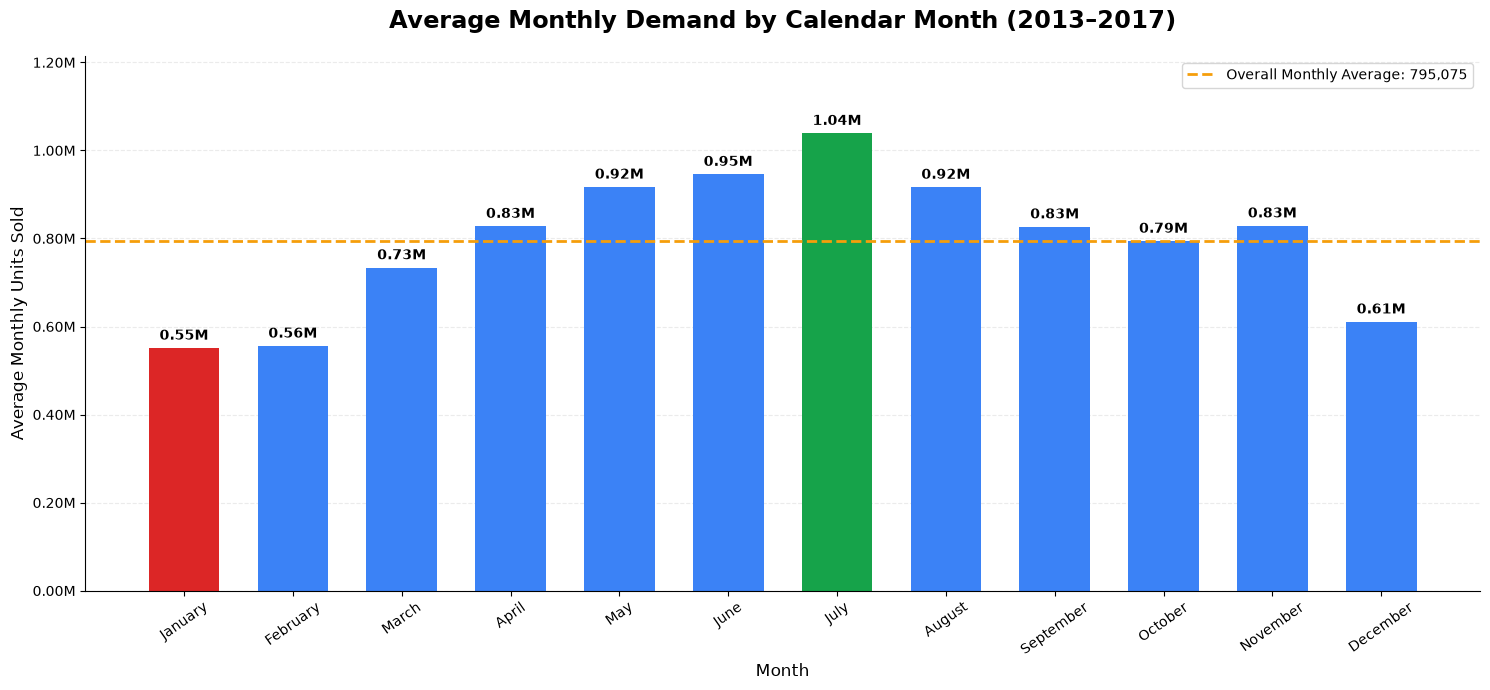

In [24]:
from matplotlib.ticker import FuncFormatter

# Define colors
colors = []

for month in seasonal_sales["Month"]:
    if month == 7:
        colors.append("#16A34A")  # Highest: July
    elif month == 1:
        colors.append("#DC2626")  # Lowest: January
    else:
        colors.append("#3B82F6")  # Other months

# Create chart
fig, ax = plt.subplots(figsize=(15, 7))

bars = ax.bar(
    seasonal_sales["Month_Name"],
    seasonal_sales["Average_Monthly_Units"],
    color=colors,
    width=0.65
)

# Add average monthly demand line
overall_average = seasonal_sales["Average_Monthly_Units"].mean()

ax.axhline(
    overall_average,
    color="#F59E0B",
    linestyle="--",
    linewidth=2,
    label=f"Overall Monthly Average: {overall_average:,.0f}"
)

# Add value labels
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 12000,
        f"{height / 1_000_000:.2f}M",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# Titles and axes
ax.set_title(
    "Average Monthly Demand by Calendar Month (2013–2017)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Average Monthly Units Sold", fontsize=12)

# Format Y-axis
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.2f}M")
)

ax.set_ylim(
    0,
    seasonal_sales["Average_Monthly_Units"].max() * 1.17
)

# Improve chart appearance
ax.tick_params(axis="x", rotation=35)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.show()

In [25]:
fig.savefig(
    "../reports/figures/month_of_year_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

print("Seasonality chart saved successfully!")

Seasonality chart saved successfully!


### 3.6 Business Insights — Month-of-Year Seasonality

**Observation 1: July Has the Highest Average Demand**

July recorded the highest average monthly unit sales at **1,038,478.60 units**, based on historical data from 2013 to 2017.

**Observation 2: January Has the Lowest Average Demand**

January recorded the lowest average monthly unit sales at **550,629.80 units**.

July's average monthly demand was approximately **88.6% higher** than January's.

**Observation 3: Demand Follows a Recurring Seasonal Pattern**

Average monthly demand generally increased from January through July before declining during the second half of the year. A modest recovery was observed in November.

This suggests a recurring seasonal pattern in historical unit sales.

**Observation 4: Several Months Exceed the Overall Average**

April, May, June, July, August, September and November recorded average monthly demand above the overall monthly average of **795,075.20 units**.

**Business Implications**

- **Inventory Planning:** Prepare for potentially higher demand during mid-year months, particularly June and July.
- **Demand Forecasting:** Incorporate calendar-month features to capture historical seasonal patterns.
- **Resource Allocation:** Consider seasonal fluctuations when planning replenishment and operational capacity.
- **Store-Level Analysis:** Investigate whether individual stores and items exhibit similar seasonal behavior.

**Limitation:** These findings are based on monthly totals averaged across five years. Differences in month length and underlying annual growth may affect the comparisons.

**Next Analysis:** Investigate weekly sales patterns and differences between weekdays and weekends.

## 4. Weekly and Weekend Demand Analysis

### 4.1 Day-of-Week Demand Analysis

**Objective:** Compare average daily unit demand across Monday–Sunday to identify weekly sales patterns.

In [27]:
import calendar

# Create a copy of daily sales data
daily_weekly = daily_sales.copy()

# Extract weekday number (Monday=0, Sunday=6)
daily_weekly["Day_of_Week"] = (
    daily_weekly["date"].dt.day_of_week
)

# Aggregate demand by weekday
weekday_sales = (
    daily_weekly.groupby("Day_of_Week")
    .agg(
        Average_Daily_Units=("Total_Units_Sold", "mean"),
        Total_Units_Sold=("Total_Units_Sold", "sum"),
        Number_of_Days=("date", "count")
    )
    .reset_index()
    .sort_values("Day_of_Week")
)

# Add readable weekday names
weekday_sales["Day_Name"] = (
    weekday_sales["Day_of_Week"]
    .map(lambda day: calendar.day_name[day])
)

# Arrange columns
weekday_sales = weekday_sales[
    [
        "Day_of_Week",
        "Day_Name",
        "Average_Daily_Units",
        "Total_Units_Sold",
        "Number_of_Days"
    ]
]

print("Weekday Sales Dataset Shape:", weekday_sales.shape)

display(
    weekday_sales.style.format({
        "Average_Daily_Units": "{:,.2f}",
        "Total_Units_Sold": "{:,.0f}"
    })
)

Weekday Sales Dataset Shape: (7, 5)


,Day_of_Week,Day_Name,Average_Daily_Units,Total_Units_Sold,Number_of_Days
0,0,Monday,"20,714.82","5,385,853",260
1,1,Tuesday,"24,112.95","6,293,481",261
2,2,Wednesday,"24,184.25","6,312,090",261
3,3,Thursday,"25,861.61","6,749,880",261
4,4,Friday,"27,578.62","7,198,021",261
5,5,Saturday,"29,331.35","7,655,482",261
6,6,Sunday,"31,071.67","8,109,705",261


In [28]:
print("========== WEEKDAY SALES VALIDATION ==========")

print("Number of Weekdays:", len(weekday_sales))

print("Total Calendar Days:",
      weekday_sales["Number_of_Days"].sum())

print("Total Units Sold:",
      weekday_sales["Total_Units_Sold"].sum())

print("Matches Original Dataset:",
      weekday_sales["Total_Units_Sold"].sum()
      == df["sales"].sum())

print("Highest Average Demand Day:")
display(
    weekday_sales.nlargest(
        1, "Average_Daily_Units"
    )
)

print("Lowest Average Demand Day:")
display(
    weekday_sales.nsmallest(
        1, "Average_Daily_Units"
    )
)

print("Missing Values:",
      weekday_sales.isnull().sum().sum())

print("========== VALIDATION COMPLETE ==========")

========== WEEKDAY SALES VALIDATION ==========
Number of Weekdays: 7
Total Calendar Days: 1826
Total Units Sold: 47704512
Matches Original Dataset: True
Highest Average Demand Day:


,Day_of_Week,Day_Name,Average_Daily_Units,Total_Units_Sold,Number_of_Days
6,6,Sunday,"31,071.67",8109705,261


Lowest Average Demand Day:


,Day_of_Week,Day_Name,Average_Daily_Units,Total_Units_Sold,Number_of_Days
0,0,Monday,"20,714.82",5385853,260


Missing Values: 0
========== VALIDATION COMPLETE ==========


In [29]:
print("========== WEEKDAY SALES SUMMARY ==========")

display(
    weekday_sales.style.format({
        "Average_Daily_Units": "{:,.2f}",
        "Total_Units_Sold": "{:,.0f}"
    })
)

========== WEEKDAY SALES SUMMARY ==========


,Day_of_Week,Day_Name,Average_Daily_Units,Total_Units_Sold,Number_of_Days
0,0,Monday,"20,714.82","5,385,853",260
1,1,Tuesday,"24,112.95","6,293,481",261
2,2,Wednesday,"24,184.25","6,312,090",261
3,3,Thursday,"25,861.61","6,749,880",261
4,4,Friday,"27,578.62","7,198,021",261
5,5,Saturday,"29,331.35","7,655,482",261
6,6,Sunday,"31,071.67","8,109,705",261


### 4.2 Weekly Demand Visualization

**Objective:** Visualize average daily units sold across Monday–Sunday to identify weekly demand patterns.

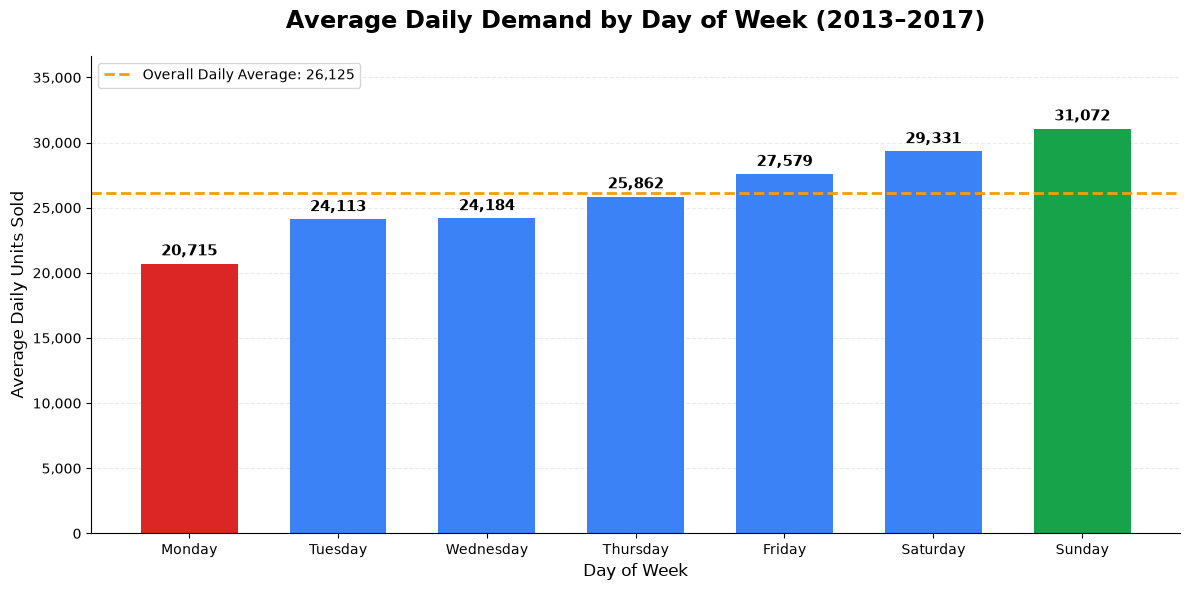

In [30]:
from matplotlib.ticker import FuncFormatter

# Highlight highest and lowest demand days
colors = []

for day in weekday_sales["Day_Name"]:
    if day == "Sunday":
        colors.append("#16A34A")
    elif day == "Monday":
        colors.append("#DC2626")
    else:
        colors.append("#3B82F6")

# Create chart
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    weekday_sales["Day_Name"],
    weekday_sales["Average_Daily_Units"],
    color=colors,
    width=0.65
)

# Add value labels
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 350,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Add overall average daily demand line
overall_avg = daily_sales["Total_Units_Sold"].mean()

ax.axhline(
    overall_avg,
    color="#F59E0B",
    linestyle="--",
    linewidth=2,
    label=f"Overall Daily Average: {overall_avg:,.0f}"
)

# Chart title and labels
ax.set_title(
    "Average Daily Demand by Day of Week (2013–2017)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Day of Week", fontsize=12)
ax.set_ylabel("Average Daily Units Sold", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

ax.set_ylim(
    0,
    weekday_sales["Average_Daily_Units"].max() * 1.18
)

# Chart styling
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

In [31]:
fig.savefig(
    "../reports/figures/weekday_demand_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

print("Weekday demand chart saved successfully!")

Weekday demand chart saved successfully!


### 4.3 Business Insights — Weekly Demand Analysis

**Observation 1: Sunday Records the Highest Average Daily Demand**

Sunday recorded the highest average daily unit sales at **31,071.67 units**, followed by Saturday at **29,331.35 units**.

**Observation 2: Monday Records the Lowest Average Daily Demand**

Monday recorded the lowest average daily unit sales at **20,714.82 units**.

Sunday's average daily demand was approximately **50% higher** than Monday's.

**Observation 3: Demand Generally Increases Throughout the Week**

Average daily sales rise from Monday through Sunday, suggesting a recurring weekly demand pattern in the historical dataset.

**Observation 4: Weekend Demand Appears Stronger**

Saturday and Sunday recorded higher average daily sales than any individual weekday. A separate weekday-versus-weekend comparison is required to quantify this difference.

**Business Implications**

- **Inventory Planning:** Consider increasing replenishment readiness before high-demand weekend periods.
- **Demand Forecasting:** Include day-of-week information as a potential predictive feature.
- **Operational Planning:** Evaluate staffing and fulfillment capacity around higher-demand days.
- **Store-Level Analysis:** Verify whether the same weekly patterns occur across individual stores and items.

**Next Analysis:** Quantify the difference between weekday and weekend average daily demand.

### 4.4 Weekday vs. Weekend Demand Analysis

**Objective:** Compare average daily unit sales between weekdays and weekends to quantify differences in demand.

In [32]:
# Create a copy of daily sales
weekend_daily = daily_sales.copy()

# Identify weekdays and weekends
weekend_daily["Day_of_Week"] = weekend_daily["date"].dt.day_of_week

weekend_daily["Day_Type"] = weekend_daily["Day_of_Week"].apply(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Calculate demand by day type
weekend_sales = (
    weekend_daily.groupby("Day_Type")
    .agg(
        Total_Units_Sold=("Total_Units_Sold", "sum"),
        Number_of_Days=("date", "count"),
        Average_Daily_Units=("Total_Units_Sold", "mean")
    )
    .reindex(["Weekday", "Weekend"])
    .reset_index()
)

print("Weekend Comparison Dataset Shape:", weekend_sales.shape)

display(
    weekend_sales.style.format({
        "Total_Units_Sold": "{:,.0f}",
        "Average_Daily_Units": "{:,.2f}"
    })
)

Weekend Comparison Dataset Shape: (2, 4)


,Day_Type,Total_Units_Sold,Number_of_Days,Average_Daily_Units
0,Weekday,"31,939,325",1304,"24,493.35"
1,Weekend,"15,765,187",522,"30,201.51"


In [33]:
weekday_avg = weekend_sales.loc[
    weekend_sales["Day_Type"] == "Weekday",
    "Average_Daily_Units"
].iloc[0]

weekend_avg = weekend_sales.loc[
    weekend_sales["Day_Type"] == "Weekend",
    "Average_Daily_Units"
].iloc[0]

weekend_premium = (
    (weekend_avg - weekday_avg) / weekday_avg
) * 100

print("========== WEEKEND DEMAND PREMIUM ==========")

print("Average Weekday Demand:", round(weekday_avg, 2))
print("Average Weekend Demand:", round(weekend_avg, 2))
print("Weekend Demand Premium:", f"{weekend_premium:+.2f}%")

print("========== CALCULATION COMPLETE ==========")

========== WEEKEND DEMAND PREMIUM ==========
Average Weekday Demand: 24493.35
Average Weekend Demand: 30201.51
Weekend Demand Premium: +23.30%
========== CALCULATION COMPLETE ==========


In [34]:
print("========== WEEKDAY VS WEEKEND VALIDATION ==========")

print("Number of Groups:", len(weekend_sales))

print("Total Calendar Days:",
      weekend_sales["Number_of_Days"].sum())

print("Total Units Sold:",
      weekend_sales["Total_Units_Sold"].sum())

print("Matches Original Dataset:",
      weekend_sales["Total_Units_Sold"].sum() == df["sales"].sum())

print("Missing Values:",
      weekend_sales.isnull().sum().sum())

print("Weekend Days:",
      weekend_sales.loc[
          weekend_sales["Day_Type"] == "Weekend",
          "Number_of_Days"
      ].iloc[0])

print("Weekday Days:",
      weekend_sales.loc[
          weekend_sales["Day_Type"] == "Weekday",
          "Number_of_Days"
      ].iloc[0])

print("========== VALIDATION COMPLETE ==========")

========== WEEKDAY VS WEEKEND VALIDATION ==========
Number of Groups: 2
Total Calendar Days: 1826
Total Units Sold: 47704512
Matches Original Dataset: True
Missing Values: 0
Weekend Days: 522
Weekday Days: 1304
========== VALIDATION COMPLETE ==========


In [35]:
print("========== WEEKDAY VS WEEKEND SUMMARY ==========")

print(
    weekend_sales.to_string(
        index=False,
        formatters={
            "Total_Units_Sold": "{:,.0f}".format,
            "Average_Daily_Units": "{:,.2f}".format
        }
    )
)

print("\n========== WEEKEND DEMAND PREMIUM ==========")

print("Average Weekday Demand:", round(weekday_avg, 2))
print("Average Weekend Demand:", round(weekend_avg, 2))
print("Weekend Demand Premium:", f"{weekend_premium:+.2f}%")

========== WEEKDAY VS WEEKEND SUMMARY ==========
Day_Type Total_Units_Sold  Number_of_Days Average_Daily_Units
 Weekday       31,939,325            1304           24,493.35
 Weekend       15,765,187             522           30,201.51

========== WEEKEND DEMAND PREMIUM ==========
Average Weekday Demand: 24493.35
Average Weekend Demand: 30201.51
Weekend Demand Premium: +23.30%


### 4.5 Weekday vs. Weekend Demand Visualization

**Objective:** Compare average daily unit demand between weekdays and weekends and highlight the weekend demand premium.

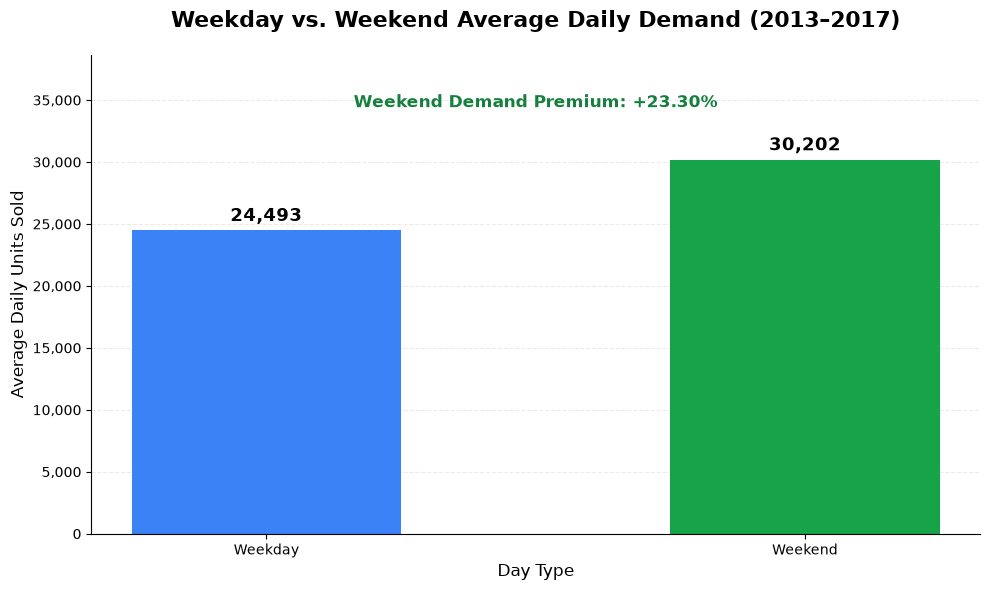

In [37]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(10, 6))

# Create comparison bars
bars = ax.bar(
    weekend_sales["Day_Type"],
    weekend_sales["Average_Daily_Units"],
    color=["#3B82F6", "#16A34A"],
    width=0.5
)

# Display average daily units above bars
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 400,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )

# Add demand premium annotation
ax.text(
    0.5,
    max(weekend_sales["Average_Daily_Units"]) * 1.14,
    f"Weekend Demand Premium: +{weekend_premium:.2f}%",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="#15803D"
)

# Chart title and labels
ax.set_title(
    "Weekday vs. Weekend Average Daily Demand (2013–2017)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Day Type", fontsize=12)
ax.set_ylabel("Average Daily Units Sold", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

ax.set_ylim(
    0,
    weekend_sales["Average_Daily_Units"].max() * 1.28
)

# Improve appearance
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [38]:
fig.savefig(
    "../reports/figures/weekday_vs_weekend_demand.png",
    dpi=300,
    bbox_inches="tight"
)

print("Weekday vs. weekend demand chart saved successfully!")

Weekday vs. weekend demand chart saved successfully!


### 4.6 Business Insights — Weekday vs. Weekend Demand

**Observation 1: Weekend Demand Is Significantly Higher**

Average daily unit sales on weekends reached **30,201.51 units**, compared with **24,493.35 units** on weekdays.

This represents a **23.30% weekend demand premium**, or approximately **5,708 additional units per day**.

**Observation 2: Weekday and Weekend Sales Contributions**

- Total weekday units sold: **31,939,325**
- Total weekend units sold: **15,765,187**
- Weekdays analyzed: **1,304 days**
- Weekend days analyzed: **522 days**

Although weekdays contributed more total units sold because they account for more calendar days, weekends recorded higher average demand per day.

**Observation 3: Weekly Seasonality Is a Potential Forecasting Feature**

The observed demand difference supports including `Day_of_Week` and `Is_Weekend` as candidate features in future demand forecasting models.

**Business Implications**

- **Inventory Planning:** Consider replenishment schedules that account for higher weekend demand.
- **Operational Capacity:** Evaluate whether additional staffing or fulfillment capacity is needed during weekends.
- **Demand Forecasting:** Test whether weekday and weekend indicators improve forecast accuracy.
- **Store and Item Analysis:** Check whether the weekend demand premium is consistent across individual stores and products.

**Limitation:** These findings describe historical aggregated demand. They do not establish that every store or item experiences the same weekend increase.

**Next Analysis:** Examine demand patterns across individual stores and items to identify differences in sales performance.

## 5. Store-Level Sales Performance Analysis

### 5.1 Store-Level Sales Aggregation

**Objective:** Evaluate total unit demand, average daily demand, and contribution to overall sales for each store from 2013 to 2017.

In [39]:
# Calculate total sales and number of records for each store
store_sales = (
    df.groupby("store")
    .agg(
        Total_Units_Sold=("sales", "sum"),
        Number_of_Records=("sales", "count"),
        Unique_Items=("item", "nunique"),
        Active_Days=("date", "nunique")
    )
    .reset_index()
)

# Calculate average daily demand per store
store_sales["Average_Daily_Units"] = (
    store_sales["Total_Units_Sold"] /
    store_sales["Active_Days"]
)

# Calculate each store's contribution to overall demand
store_sales["Sales_Contribution_Percent"] = (
    store_sales["Total_Units_Sold"] /
    df["sales"].sum() * 100
)

# Sort stores by total units sold
store_sales = (
    store_sales
    .sort_values("Total_Units_Sold", ascending=False)
    .reset_index(drop=True)
)

print("Store Sales Dataset Shape:", store_sales.shape)

display(
    store_sales.style.format({
        "Total_Units_Sold": "{:,.0f}",
        "Average_Daily_Units": "{:,.2f}",
        "Sales_Contribution_Percent": "{:.2f}%"
    })
)

Store Sales Dataset Shape: (10, 7)


,store,Total_Units_Sold,Number_of_Records,Unique_Items,Active_Days,Average_Daily_Units,Sales_Contribution_Percent
0,2,"6,120,128",91300,50,1826,"3,351.66",12.83%
1,8,"5,856,169",91300,50,1826,"3,207.10",12.28%
2,3,"5,435,144",91300,50,1826,"2,976.53",11.39%
3,10,"5,360,158",91300,50,1826,"2,935.46",11.24%
4,9,"5,025,976",91300,50,1826,"2,752.45",10.54%
5,4,"5,012,639",91300,50,1826,"2,745.15",10.51%
6,1,"4,315,603",91300,50,1826,"2,363.42",9.05%
7,5,"3,631,016",91300,50,1826,"1,988.51",7.61%
8,6,"3,627,670",91300,50,1826,"1,986.68",7.60%
9,7,"3,320,009",91300,50,1826,"1,818.19",6.96%


In [40]:
print("========== STORE SALES VALIDATION ==========")

print("Number of Stores:", len(store_sales))

print("Total Units Sold:",
      store_sales["Total_Units_Sold"].sum())

print("Matches Original Dataset:",
      store_sales["Total_Units_Sold"].sum() == df["sales"].sum())

print("Total Sales Contribution (%):",
      round(store_sales["Sales_Contribution_Percent"].sum(), 2))

print("All Stores Have 50 Items:",
      (store_sales["Unique_Items"] == 50).all())

print("All Stores Have 1826 Days:",
      (store_sales["Active_Days"] == 1826).all())

print("Missing Values:",
      store_sales.isnull().sum().sum())

print("\nHighest Demand Store:")
display(store_sales.nlargest(1, "Total_Units_Sold"))

print("\nLowest Demand Store:")
display(store_sales.nsmallest(1, "Total_Units_Sold"))

print("========== VALIDATION COMPLETE ==========")

========== STORE SALES VALIDATION ==========
Number of Stores: 10
Total Units Sold: 47704512
Matches Original Dataset: True
Total Sales Contribution (%): 100.0
All Stores Have 50 Items: True
All Stores Have 1826 Days: True
Missing Values: 0

Highest Demand Store:


,store,Total_Units_Sold,Number_of_Records,Unique_Items,Active_Days,Average_Daily_Units,Sales_Contribution_Percent
0,2,6120128,91300,50,1826,"3,351.66",12.83



Lowest Demand Store:


,store,Total_Units_Sold,Number_of_Records,Unique_Items,Active_Days,Average_Daily_Units,Sales_Contribution_Percent
9,7,3320009,91300,50,1826,"1,818.19",6.96


========== VALIDATION COMPLETE ==========


In [41]:
print("========== STORE SALES RANKING ==========")

print(
    store_sales[
        [
            "store",
            "Total_Units_Sold",
            "Average_Daily_Units",
            "Sales_Contribution_Percent"
        ]
    ].to_string(
        index=False,
        formatters={
            "Total_Units_Sold": "{:,.0f}".format,
            "Average_Daily_Units": "{:,.2f}".format,
            "Sales_Contribution_Percent": "{:.2f}%".format
        }
    )
)

print("========== RANKING COMPLETE ==========")

========== STORE SALES RANKING ==========
 store Total_Units_Sold Average_Daily_Units Sales_Contribution_Percent
     2        6,120,128            3,351.66                     12.83%
     8        5,856,169            3,207.10                     12.28%
     3        5,435,144            2,976.53                     11.39%
    10        5,360,158            2,935.46                     11.24%
     9        5,025,976            2,752.45                     10.54%
     4        5,012,639            2,745.15                     10.51%
     1        4,315,603            2,363.42                      9.05%
     5        3,631,016            1,988.51                      7.61%
     6        3,627,670            1,986.68                      7.60%
     7        3,320,009            1,818.19                      6.96%
========== RANKING COMPLETE ==========


### 5.2 Store-Level Sales Visualization

**Objective:** Compare total units sold across all 10 stores and highlight the highest- and lowest-demand stores.

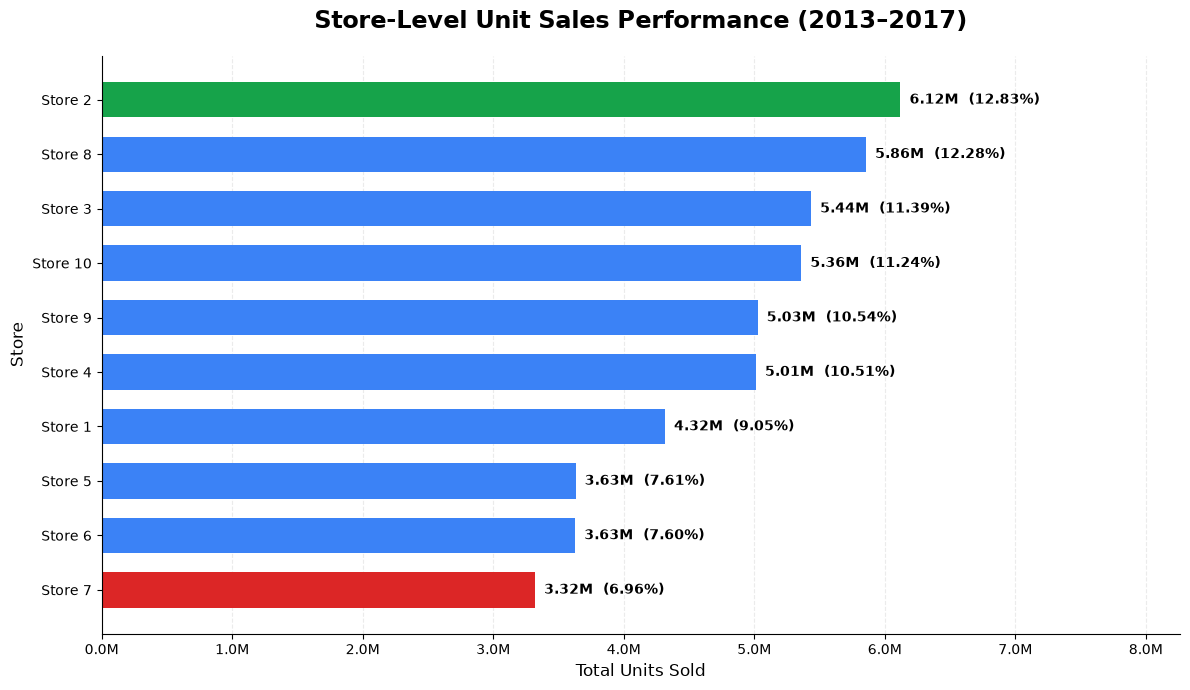

In [42]:
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plt

# Sort stores from lowest to highest for horizontal plotting
store_chart = store_sales.sort_values(
    "Total_Units_Sold", ascending=True
).copy()

# Highlight highest and lowest demand stores
colors = []

for store in store_chart["store"]:
    if store == 2:
        colors.append("#16A34A")  # Highest demand
    elif store == 7:
        colors.append("#DC2626")  # Lowest demand
    else:
        colors.append("#3B82F6")  # Other stores

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    store_chart["store"].apply(lambda x: f"Store {x}"),
    store_chart["Total_Units_Sold"],
    color=colors,
    height=0.65
)

# Add unit sales and contribution percentage labels
for bar, (_, row) in zip(bars, store_chart.iterrows()):
    width = bar.get_width()

    ax.text(
        width + 70000,
        bar.get_y() + bar.get_height() / 2,
        f"{width / 1_000_000:.2f}M  "
        f"({row['Sales_Contribution_Percent']:.2f}%)",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Store-Level Unit Sales Performance (2013–2017)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Total Units Sold", fontsize=12)
ax.set_ylabel("Store", fontsize=12)

# Format X-axis in millions
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.1f}M")
)

# Leave room for data labels
ax.set_xlim(
    0,
    store_chart["Total_Units_Sold"].max() * 1.35
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [43]:
fig.savefig(
    "../reports/figures/store_sales_performance.png",
    dpi=300,
    bbox_inches="tight"
)

print("Store sales performance chart saved successfully!")

Store sales performance chart saved successfully!


### 5.3 Business Insights — Store-Level Sales Performance

**Observation 1: Store 2 Records the Highest Unit Demand**

Store 2 recorded the highest total unit sales at **6,120,128 units**, contributing **12.83%** of overall demand between 2013 and 2017.

Its average daily demand was approximately **3,351.66 units**.

**Observation 2: Store 7 Records the Lowest Unit Demand**

Store 7 recorded the lowest total unit sales at **3,320,009 units**, contributing **6.96%** of overall demand.

Its average daily demand was approximately **1,818.19 units**.

**Observation 3: Significant Demand Differences Between Stores**

Store 2 sold approximately **84.3% more units** than Store 7 during the same period.

All 10 stores contain 50 items and have 1,826 days of recorded sales, making their observed demand levels directly comparable.

**Observation 4: Demand Is Concentrated Among Leading Stores**

Stores 2, 8 and 3 collectively contributed approximately **36.5% of total unit sales**.

This indicates that a relatively small group of stores accounts for a substantial portion of overall demand.

**Business Implications**

- **Inventory Allocation:** Consider store-specific demand when planning stock distribution.
- **Demand Forecasting:** Evaluate store identifiers and store-level historical patterns as forecasting features.
- **Operational Planning:** Investigate whether higher-demand stores require greater replenishment and fulfillment capacity.
- **Performance Analysis:** Explore potential reasons for demand differences before drawing conclusions about store efficiency.

**Limitations**

The dataset contains unit sales but does not include product prices, profit margins, store size, foot traffic or stock availability. Therefore, higher sales volume should not automatically be interpreted as higher profitability or operational efficiency.

**Next Analysis:** Examine item-level sales performance to identify the highest- and lowest-demand products.

## 6. Item-Level Sales Performance Analysis

### 6.1 Item-Level Sales Aggregation

**Objective:** Analyze total unit demand, average daily demand, and sales contribution across all 50 items from 2013 to 2017.

In [44]:
# Calculate item-level sales performance
item_sales = (
    df.groupby("item")
    .agg(
        Total_Units_Sold=("sales", "sum"),
        Number_of_Records=("sales", "count"),
        Unique_Stores=("store", "nunique"),
        Active_Days=("date", "nunique")
    )
    .reset_index()
)

# Calculate average daily demand across all stores
item_sales["Average_Daily_Units"] = (
    item_sales["Total_Units_Sold"] /
    item_sales["Active_Days"]
)

# Calculate each item's contribution to overall demand
item_sales["Sales_Contribution_Percent"] = (
    item_sales["Total_Units_Sold"] /
    df["sales"].sum() * 100
)

# Rank items by total units sold
item_sales = (
    item_sales
    .sort_values("Total_Units_Sold", ascending=False)
    .reset_index(drop=True)
)

print("Item Sales Dataset Shape:", item_sales.shape)

display(
    item_sales.head(10).style.format({
        "Total_Units_Sold": "{:,.0f}",
        "Average_Daily_Units": "{:,.2f}",
        "Sales_Contribution_Percent": "{:.2f}%"
    })
)

Item Sales Dataset Shape: (50, 7)


,item,Total_Units_Sold,Number_of_Records,Unique_Stores,Active_Days,Average_Daily_Units,Sales_Contribution_Percent
0,15,"1,607,442",18260,10,1826,880.31,3.37%
1,28,"1,604,713",18260,10,1826,878.81,3.36%
2,13,"1,539,621",18260,10,1826,843.17,3.23%
3,18,"1,538,876",18260,10,1826,842.76,3.23%
4,25,"1,473,334",18260,10,1826,806.86,3.09%
5,45,"1,471,467",18260,10,1826,805.84,3.08%
6,38,"1,470,330",18260,10,1826,805.22,3.08%
7,22,"1,469,971",18260,10,1826,805.02,3.08%
8,36,"1,406,548",18260,10,1826,770.29,2.95%
9,8,"1,405,108",18260,10,1826,769.50,2.95%


In [45]:
print("========== ITEM SALES VALIDATION ==========")

print("Number of Items:", len(item_sales))

print("Total Units Sold:",
      item_sales["Total_Units_Sold"].sum())

print("Matches Original Dataset:",
      item_sales["Total_Units_Sold"].sum() == df["sales"].sum())

print("Total Sales Contribution (%):",
      round(item_sales["Sales_Contribution_Percent"].sum(), 2))

print("All Items Have 10 Stores:",
      (item_sales["Unique_Stores"] == 10).all())

print("All Items Have 1826 Days:",
      (item_sales["Active_Days"] == 1826).all())

print("Missing Values:",
      item_sales.isnull().sum().sum())

print("\nHighest Demand Item:")
display(item_sales.nlargest(1, "Total_Units_Sold"))

print("\nLowest Demand Item:")
display(item_sales.nsmallest(1, "Total_Units_Sold"))

print("========== VALIDATION COMPLETE ==========")

========== ITEM SALES VALIDATION ==========
Number of Items: 50
Total Units Sold: 47704512
Matches Original Dataset: True
Total Sales Contribution (%): 100.0
All Items Have 10 Stores: True
All Items Have 1826 Days: True
Missing Values: 0

Highest Demand Item:


,item,Total_Units_Sold,Number_of_Records,Unique_Stores,Active_Days,Average_Daily_Units,Sales_Contribution_Percent
0,15,1607442,18260,10,1826,880.31,3.37



Lowest Demand Item:


,item,Total_Units_Sold,Number_of_Records,Unique_Stores,Active_Days,Average_Daily_Units,Sales_Contribution_Percent
49,5,335230,18260,10,1826,183.59,0.70


========== VALIDATION COMPLETE ==========


### 6.2 Top 10 and Bottom 10 Items by Unit Demand

**Objective:** Identify the highest- and lowest-demand items using total units sold across all stores from 2013 to 2017.

In [46]:
print("========== TOP 10 ITEMS ==========")

top_10_items = item_sales.nlargest(
    10, "Total_Units_Sold"
)

print(
    top_10_items[
        [
            "item",
            "Total_Units_Sold",
            "Average_Daily_Units",
            "Sales_Contribution_Percent"
        ]
    ].to_string(
        index=False,
        formatters={
            "Total_Units_Sold": "{:,.0f}".format,
            "Average_Daily_Units": "{:,.2f}".format,
            "Sales_Contribution_Percent": "{:.2f}%".format
        }
    )
)

========== TOP 10 ITEMS ==========
 item Total_Units_Sold Average_Daily_Units Sales_Contribution_Percent
   15        1,607,442              880.31                      3.37%
   28        1,604,713              878.81                      3.36%
   13        1,539,621              843.17                      3.23%
   18        1,538,876              842.76                      3.23%
   25        1,473,334              806.86                      3.09%
   45        1,471,467              805.84                      3.08%
   38        1,470,330              805.22                      3.08%
   22        1,469,971              805.02                      3.08%
   36        1,406,548              770.29                      2.95%
    8        1,405,108              769.50                      2.95%


In [47]:
print("========== BOTTOM 10 ITEMS ==========")

bottom_10_items = item_sales.nsmallest(
    10, "Total_Units_Sold"
)

print(
    bottom_10_items[
        [
            "item",
            "Total_Units_Sold",
            "Average_Daily_Units",
            "Sales_Contribution_Percent"
        ]
    ].to_string(
        index=False,
        formatters={
            "Total_Units_Sold": "{:,.0f}".format,
            "Average_Daily_Units": "{:,.2f}".format,
            "Sales_Contribution_Percent": "{:.2f}%".format
        }
    )
)

========== BOTTOM 10 ITEMS ==========
 item Total_Units_Sold Average_Daily_Units Sales_Contribution_Percent
    5          335,230              183.59                      0.70%
    1          401,384              219.82                      0.84%
   41          401,759              220.02                      0.84%
   47          401,781              220.03                      0.84%
    4          401,907              220.10                      0.84%
   27          402,628              220.50                      0.84%
   16          468,480              256.56                      0.98%
   34          469,935              257.36                      0.99%
   40          534,094              292.49                      1.12%
   37          534,258              292.58                      1.12%


In [48]:
print("========== ITEM RANKING VALIDATION ==========")

print("Top 10 Count:", len(top_10_items))
print("Bottom 10 Count:", len(bottom_10_items))

print("Highest Demand Item:",
      top_10_items.iloc[0]["item"])

print("Lowest Demand Item:",
      bottom_10_items.iloc[0]["item"])

print("Overlapping Items:",
      len(
          set(top_10_items["item"]) &
          set(bottom_10_items["item"])
      ))

print("========== VALIDATION COMPLETE ==========")


========== ITEM RANKING VALIDATION ==========
Top 10 Count: 10
Bottom 10 Count: 10
Highest Demand Item: 15.0
Lowest Demand Item: 5.0
Overlapping Items: 0
========== VALIDATION COMPLETE ==========


In [49]:
print("Highest Demand Item:",
      int(top_10_items.iloc[0]["item"]))

print("Lowest Demand Item:",
      int(bottom_10_items.iloc[0]["item"]))

Highest Demand Item: 15
Lowest Demand Item: 5


In [50]:
print("========== TOP 10 ITEMS ==========")

display(
    top_10_items[
        ["item", "Total_Units_Sold",
         "Average_Daily_Units",
         "Sales_Contribution_Percent"]
    ]
)

print("========== BOTTOM 10 ITEMS ==========")

display(
    bottom_10_items[
        ["item", "Total_Units_Sold",
         "Average_Daily_Units",
         "Sales_Contribution_Percent"]
    ]
)

========== TOP 10 ITEMS ==========


,item,Total_Units_Sold,Average_Daily_Units,Sales_Contribution_Percent
0,15,1607442,880.31,3.37
1,28,1604713,878.81,3.36
2,13,1539621,843.17,3.23
3,18,1538876,842.76,3.23
4,25,1473334,806.86,3.09
5,45,1471467,805.84,3.08
6,38,1470330,805.22,3.08
7,22,1469971,805.02,3.08
8,36,1406548,770.29,2.95
9,8,1405108,769.50,2.95


========== BOTTOM 10 ITEMS ==========


,item,Total_Units_Sold,Average_Daily_Units,Sales_Contribution_Percent
49,5,335230,183.59,0.70
48,1,401384,219.82,0.84
47,41,401759,220.02,0.84
46,47,401781,220.03,0.84
45,4,401907,220.10,0.84
44,27,402628,220.50,0.84
43,16,468480,256.56,0.98
42,34,469935,257.36,0.99
41,40,534094,292.49,1.12
40,37,534258,292.58,1.12


### 6.3 Top 10 Item Sales Visualization

**Objective:** Compare the 10 highest-demand items by total units sold and highlight the leading item.

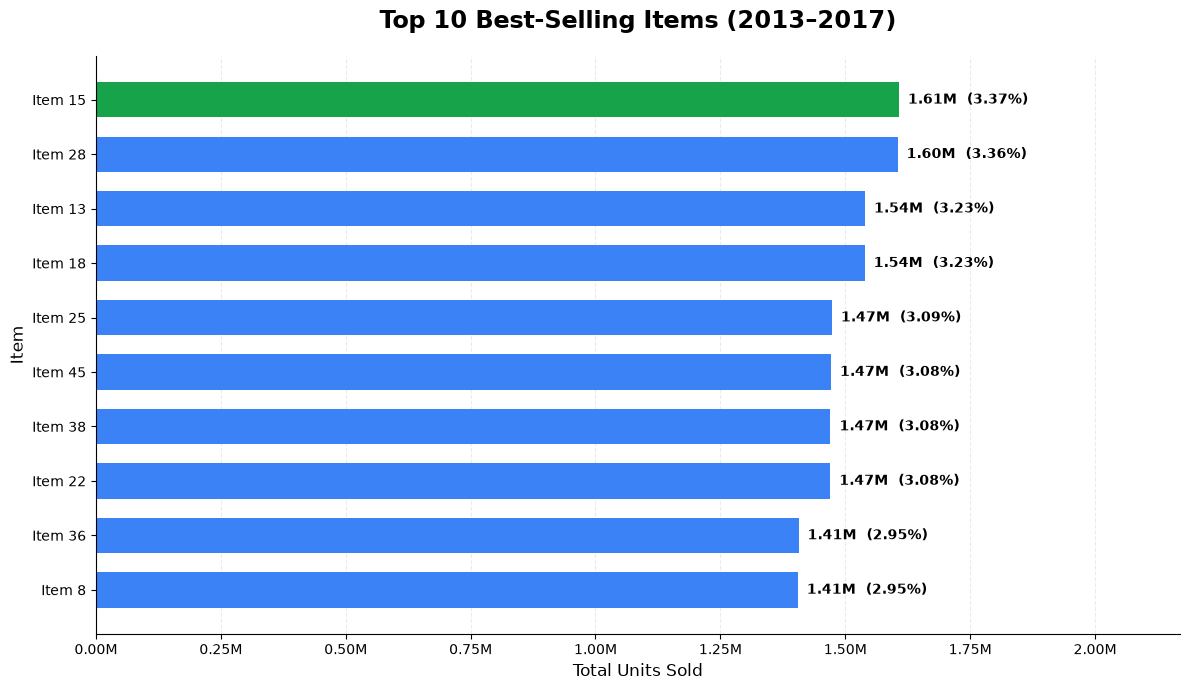

In [52]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Sort for horizontal plotting
top_items_chart = top_10_items.sort_values(
    "Total_Units_Sold", ascending=True
).copy()

# Highlight Item 15
colors = [
    "#16A34A" if item == 15 else "#3B82F6"
    for item in top_items_chart["item"]
]

# Create chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_items_chart["item"].apply(lambda x: f"Item {int(x)}"),
    top_items_chart["Total_Units_Sold"],
    color=colors,
    height=0.65
)

# Add sales values and contribution percentages
for bar, (_, row) in zip(bars, top_items_chart.iterrows()):
    width = bar.get_width()

    ax.text(
        width + 18000,
        bar.get_y() + bar.get_height() / 2,
        f"{width / 1_000_000:.2f}M  "
        f"({row['Sales_Contribution_Percent']:.2f}%)",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

# Chart title
ax.set_title(
    "Top 10 Best-Selling Items (2013–2017)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Total Units Sold", fontsize=12)
ax.set_ylabel("Item", fontsize=12)

# Format X-axis
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.2f}M")
)

# Leave space for labels
ax.set_xlim(
    0,
    top_items_chart["Total_Units_Sold"].max() * 1.35
)

# Improve chart appearance
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [53]:
fig.savefig(
    "../reports/figures/top_10_items_sales.png",
    dpi=300,
    bbox_inches="tight"
)

print("Top 10 item sales chart saved successfully!")

Top 10 item sales chart saved successfully!


### 6.4 Bottom 10 Item Sales Visualization

**Objective:** Identify and visualize the 10 lowest-demand items to support item-level demand forecasting and inventory planning.

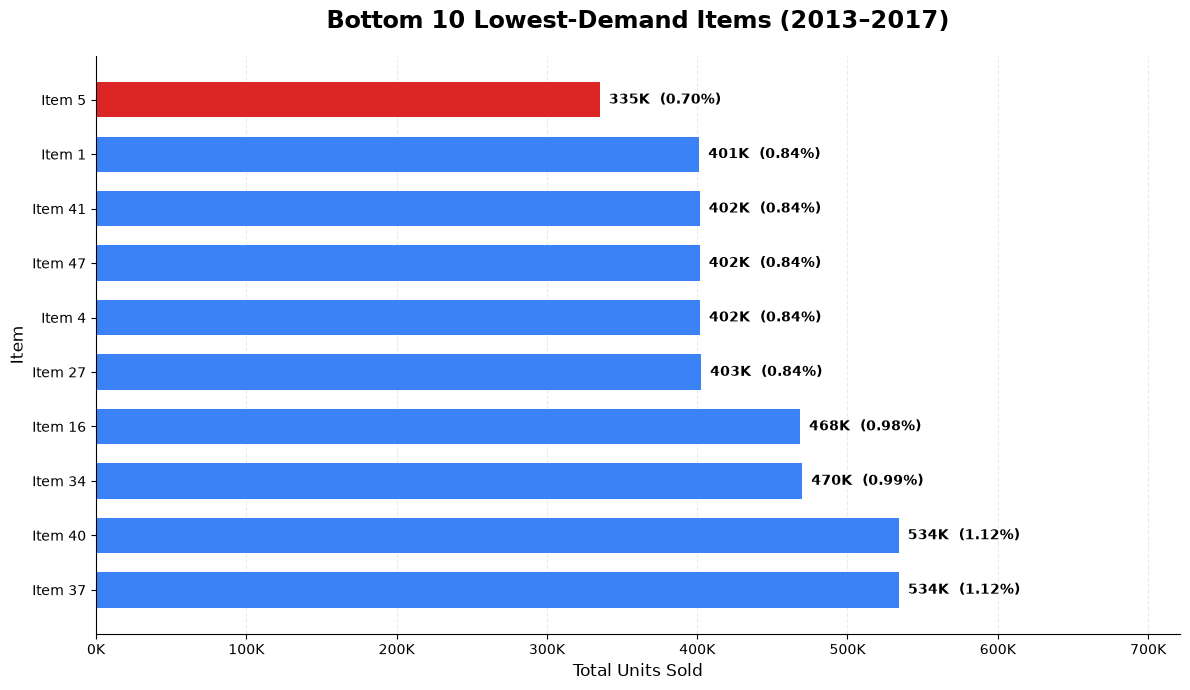

In [54]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Sort bottom 10 items from lowest to highest
bottom_items_chart = bottom_10_items.sort_values(
    "Total_Units_Sold",
    ascending=False
).copy()

# Highlight the lowest-demand item
colors = [
    "#DC2626" if item == 5 else "#3B82F6"
    for item in bottom_items_chart["item"]
]

# Create chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    bottom_items_chart["item"].apply(
        lambda x: f"Item {int(x)}"
    ),
    bottom_items_chart["Total_Units_Sold"],
    color=colors,
    height=0.65
)

# Add data labels
for bar, (_, row) in zip(bars, bottom_items_chart.iterrows()):
    width = bar.get_width()

    ax.text(
        width + 6000,
        bar.get_y() + bar.get_height() / 2,
        f"{width / 1000:,.0f}K  "
        f"({row['Sales_Contribution_Percent']:.2f}%)",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

# Chart title and axis labels
ax.set_title(
    "Bottom 10 Lowest-Demand Items (2013–2017)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Total Units Sold", fontsize=12)
ax.set_ylabel("Item", fontsize=12)

# Format X-axis in thousands
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1000:,.0f}K")
)

# Leave space for labels
ax.set_xlim(
    0,
    bottom_items_chart["Total_Units_Sold"].max() * 1.35
)

# Styling
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [55]:
fig.savefig(
    "../reports/figures/bottom_10_items_sales.png",
    dpi=300,
    bbox_inches="tight"
)

print("Bottom 10 item sales chart saved successfully!")

Bottom 10 item sales chart saved successfully!


### 6.5 Business Insights — Item-Level Sales Performance

**Observation 1: Item 15 Records the Highest Unit Demand**

Item 15 recorded the highest total unit sales at **1,607,442 units**, contributing approximately **3.37%** of total demand between 2013 and 2017.

Item 28 followed closely with **1,604,713 units**, representing approximately **3.36%** of overall demand.

The small difference between these items indicates that both experienced similar historical sales volumes.

**Observation 2: Item 5 Records the Lowest Unit Demand**

Item 5 recorded the lowest total unit sales at **335,230 units**, contributing approximately **0.70%** of overall demand.

Its average daily demand across all stores was approximately **183.59 units**.

**Observation 3: Substantial Differences in Item Demand**

Item 15 sold approximately **4.79 times** as many units as Item 5 during the analysis period.

Both items were recorded across all 10 stores and 1,826 calendar days, allowing a consistent comparison of their historical demand.

**Observation 4: Leading Items Contribute a Meaningful Share of Demand**

The Top 10 items collectively contributed approximately **31.43%** of total unit sales.

This suggests that a subset of items accounts for a substantial share of overall demand, although sales are also distributed across the remaining 40 items.

**Business Implications**

- **Inventory Planning:** Consider item-specific replenishment quantities rather than uniform stock allocation.
- **Demand Forecasting:** Develop or evaluate forecasts at the item or store-item level to capture differences in demand.
- **Inventory Prioritization:** Investigate whether consistently high-demand items require closer stock monitoring.
- **Low-Demand Item Management:** Review inventory levels and turnover for lower-demand items before making stocking decisions.
- **Store-Item Analysis:** Examine whether high-demand items perform consistently across different stores.

**Limitations**

The dataset provides item identifiers and unit sales but does not contain product names, selling prices, inventory levels, profit margins, or stockout information. Therefore, low sales volume does not necessarily indicate poor profitability or excess inventory.

**Next Analysis:** Investigate store-item demand combinations to understand differences in product demand across individual stores.

## 7. Store-Item Demand Analysis

### 7.1 Store-Item Demand Aggregation

**Objective:** Analyze historical unit demand for all 500 store-item combinations and identify differences in demand across stores and items.

In [56]:
# Calculate store-item demand performance
store_item_sales = (
    df.groupby(["store", "item"])
    .agg(
        Total_Units_Sold=("sales", "sum"),
        Number_of_Records=("sales", "count"),
        Active_Days=("date", "nunique")
    )
    .reset_index()
)

# Calculate average daily units sold
store_item_sales["Average_Daily_Units"] = (
    store_item_sales["Total_Units_Sold"] /
    store_item_sales["Active_Days"]
)

# Calculate store-level total demand
store_totals = (
    df.groupby("store")["sales"]
    .sum()
)

# Calculate contribution of each item within its store
store_item_sales["Store_Sales_Contribution_Percent"] = (
    store_item_sales["Total_Units_Sold"] /
    store_item_sales["store"].map(store_totals)
) * 100

# Rank combinations by total units sold
store_item_sales = (
    store_item_sales
    .sort_values(
        "Total_Units_Sold",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Store-Item Dataset Shape:", store_item_sales.shape)

print("\nFirst 10 Store-Item Combinations:")

display(
    store_item_sales.head(10).style.format({
        "Total_Units_Sold": "{:,.0f}",
        "Average_Daily_Units": "{:,.2f}",
        "Store_Sales_Contribution_Percent": "{:.2f}%"
    })
)

Store-Item Dataset Shape: (500, 7)

First 10 Store-Item Combinations:


,store,item,Total_Units_Sold,Number_of_Records,Active_Days,Average_Daily_Units,Store_Sales_Contribution_Percent
0,2,28,"205,677",1826,1826,112.64,3.36%
1,2,15,"205,569",1826,1826,112.58,3.36%
2,2,18,"197,422",1826,1826,108.12,3.23%
3,8,15,"197,295",1826,1826,108.05,3.37%
4,2,13,"197,031",1826,1826,107.90,3.22%
5,8,28,"196,867",1826,1826,107.81,3.36%
6,8,18,"189,576",1826,1826,103.82,3.24%
7,8,13,"189,575",1826,1826,103.82,3.24%
8,2,25,"188,856",1826,1826,103.43,3.09%
9,2,45,"188,774",1826,1826,103.38,3.08%


In [57]:
print("========== STORE-ITEM VALIDATION ==========")

print("Total Combinations:",
      len(store_item_sales))

print("Unique Stores:",
      store_item_sales["store"].nunique())

print("Unique Items:",
      store_item_sales["item"].nunique())

print("Total Units Sold:",
      store_item_sales["Total_Units_Sold"].sum())

print("Matches Original Dataset:",
      store_item_sales["Total_Units_Sold"].sum()
      == df["sales"].sum())

print("All Combinations Have 1826 Days:",
      (store_item_sales["Active_Days"] == 1826).all())

print("All Combinations Have 1826 Records:",
      (store_item_sales["Number_of_Records"] == 1826).all())

print("Missing Values:",
      store_item_sales.isnull().sum().sum())

print("Duplicate Store-Item Keys:",
      store_item_sales.duplicated(
          subset=["store", "item"]
      ).sum())

print("Contribution Sums to 100% Per Store:",
      store_item_sales.groupby("store")[
          "Store_Sales_Contribution_Percent"
      ].sum().round(2).eq(100).all())

print("\nHighest Demand Combination:")
display(
    store_item_sales.nlargest(
        1, "Total_Units_Sold"
    )
)

print("\nLowest Demand Combination:")
display(
    store_item_sales.nsmallest(
        1, "Total_Units_Sold"
    )
)

print("========== VALIDATION COMPLETE ==========")

========== STORE-ITEM VALIDATION ==========
Total Combinations: 500
Unique Stores: 10
Unique Items: 50
Total Units Sold: 47704512
Matches Original Dataset: True
All Combinations Have 1826 Days: True
All Combinations Have 1826 Records: True
Missing Values: 0
Duplicate Store-Item Keys: 0
Contribution Sums to 100% Per Store: True

Highest Demand Combination:


,store,item,Total_Units_Sold,Number_of_Records,Active_Days,Average_Daily_Units,Store_Sales_Contribution_Percent
0,2,28,205677,1826,1826,112.64,3.36



Lowest Demand Combination:


,store,item,Total_Units_Sold,Number_of_Records,Active_Days,Average_Daily_Units,Store_Sales_Contribution_Percent
499,7,5,23252,1826,1826,12.73,0.70


========== VALIDATION COMPLETE ==========


### 7.2 Top 10 and Bottom 10 Store-Item Combinations

**Objective:** Identify the highest- and lowest-demand store-item combinations using total historical units sold.

In [58]:
top_10_store_items = store_item_sales.nlargest(
    10, "Total_Units_Sold"
).copy()

print("========== TOP 10 STORE-ITEM COMBINATIONS ==========")

display(
    top_10_store_items[
        [
            "store",
            "item",
            "Total_Units_Sold",
            "Average_Daily_Units",
            "Store_Sales_Contribution_Percent"
        ]
    ].style.format({
        "Total_Units_Sold": "{:,.0f}",
        "Average_Daily_Units": "{:,.2f}",
        "Store_Sales_Contribution_Percent": "{:.2f}%"
    })
)

========== TOP 10 STORE-ITEM COMBINATIONS ==========


,store,item,Total_Units_Sold,Average_Daily_Units,Store_Sales_Contribution_Percent
0,2,28,"205,677",112.64,3.36%
1,2,15,"205,569",112.58,3.36%
2,2,18,"197,422",108.12,3.23%
3,8,15,"197,295",108.05,3.37%
4,2,13,"197,031",107.90,3.22%
5,8,28,"196,867",107.81,3.36%
6,8,18,"189,576",103.82,3.24%
7,8,13,"189,575",103.82,3.24%
8,2,25,"188,856",103.43,3.09%
9,2,45,"188,774",103.38,3.08%


In [59]:
bottom_10_store_items = store_item_sales.nsmallest(
    10, "Total_Units_Sold"
).copy()

print("========== BOTTOM 10 STORE-ITEM COMBINATIONS ==========")

display(
    bottom_10_store_items[
        [
            "store",
            "item",
            "Total_Units_Sold",
            "Average_Daily_Units",
            "Store_Sales_Contribution_Percent"
        ]
    ].style.format({
        "Total_Units_Sold": "{:,.0f}",
        "Average_Daily_Units": "{:,.2f}",
        "Store_Sales_Contribution_Percent": "{:.2f}%"
    })
)

========== BOTTOM 10 STORE-ITEM COMBINATIONS ==========


,store,item,Total_Units_Sold,Average_Daily_Units,Store_Sales_Contribution_Percent
499,7,5,"23,252",12.73,0.70%
498,6,5,"25,369",13.89,0.70%
497,5,5,"25,722",14.09,0.71%
496,7,1,"27,681",15.16,0.83%
495,7,27,"27,780",15.21,0.84%
494,7,4,"28,044",15.36,0.84%
493,7,41,"28,251",15.47,0.85%
492,7,47,"28,265",15.48,0.85%
491,6,41,"30,325",16.61,0.84%
490,1,5,"30,335",16.61,0.70%


In [60]:
print("========== STORE-ITEM RANKING VALIDATION ==========")

print("Top 10 Count:", len(top_10_store_items))
print("Bottom 10 Count:", len(bottom_10_store_items))

print(
    "Highest Demand Combination:",
    tuple(
        top_10_store_items.iloc[0][["store", "item"]]
        .astype(int)
    )
)

print(
    "Lowest Demand Combination:",
    tuple(
        bottom_10_store_items.iloc[0][["store", "item"]]
        .astype(int)
    )
)

top_keys = set(
    zip(top_10_store_items["store"], top_10_store_items["item"])
)

bottom_keys = set(
    zip(bottom_10_store_items["store"], bottom_10_store_items["item"])
)

print("Overlapping Combinations:", len(top_keys & bottom_keys))

print("========== VALIDATION COMPLETE ==========")

========== STORE-ITEM RANKING VALIDATION ==========
Top 10 Count: 10
Bottom 10 Count: 10
Highest Demand Combination: (2, 28)
Lowest Demand Combination: (7, 5)
Overlapping Combinations: 0
========== VALIDATION COMPLETE ==========


In [61]:
print("========== TOP 10 STORE-ITEM COMBINATIONS ==========")

display(
    top_10_store_items[
        [
            "store",
            "item",
            "Total_Units_Sold",
            "Average_Daily_Units",
            "Store_Sales_Contribution_Percent"
        ]
    ].style.format({
        "Total_Units_Sold": "{:,.0f}",
        "Average_Daily_Units": "{:,.2f}",
        "Store_Sales_Contribution_Percent": "{:.2f}%"
    })
)

print("========== BOTTOM 10 STORE-ITEM COMBINATIONS ==========")

display(
    bottom_10_store_items[
        [
            "store",
            "item",
            "Total_Units_Sold",
            "Average_Daily_Units",
            "Store_Sales_Contribution_Percent"
        ]
    ].style.format({
        "Total_Units_Sold": "{:,.0f}",
        "Average_Daily_Units": "{:,.2f}",
        "Store_Sales_Contribution_Percent": "{:.2f}%"
    })
)

========== TOP 10 STORE-ITEM COMBINATIONS ==========


,store,item,Total_Units_Sold,Average_Daily_Units,Store_Sales_Contribution_Percent
0,2,28,"205,677",112.64,3.36%
1,2,15,"205,569",112.58,3.36%
2,2,18,"197,422",108.12,3.23%
3,8,15,"197,295",108.05,3.37%
4,2,13,"197,031",107.90,3.22%
5,8,28,"196,867",107.81,3.36%
6,8,18,"189,576",103.82,3.24%
7,8,13,"189,575",103.82,3.24%
8,2,25,"188,856",103.43,3.09%
9,2,45,"188,774",103.38,3.08%


========== BOTTOM 10 STORE-ITEM COMBINATIONS ==========


,store,item,Total_Units_Sold,Average_Daily_Units,Store_Sales_Contribution_Percent
499,7,5,"23,252",12.73,0.70%
498,6,5,"25,369",13.89,0.70%
497,5,5,"25,722",14.09,0.71%
496,7,1,"27,681",15.16,0.83%
495,7,27,"27,780",15.21,0.84%
494,7,4,"28,044",15.36,0.84%
493,7,41,"28,251",15.47,0.85%
492,7,47,"28,265",15.48,0.85%
491,6,41,"30,325",16.61,0.84%
490,1,5,"30,335",16.61,0.70%


### 7.3 Top 10 Store-Item Demand Visualization

**Objective:** Compare the 10 highest-demand store-item combinations and highlight the leading combination.

**Metric:** Total units sold from 2013 to 2017.

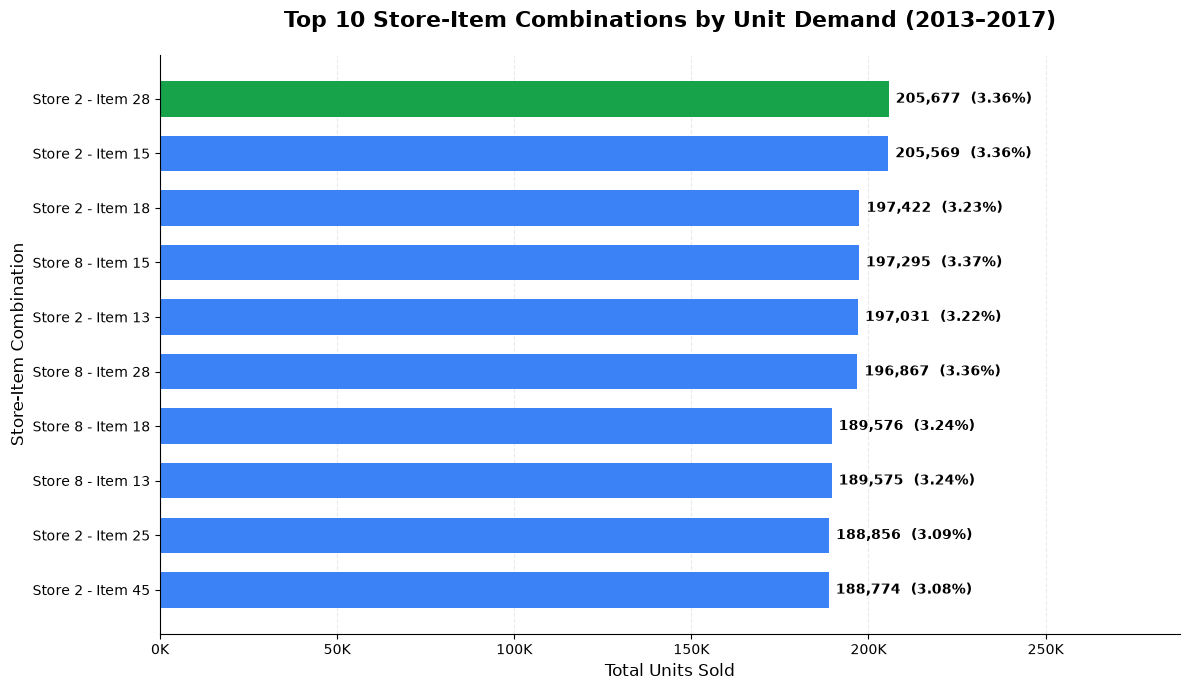

In [62]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Prepare Top 10 combinations for horizontal plotting
top_store_item_chart = (
    top_10_store_items
    .sort_values("Total_Units_Sold", ascending=True)
    .copy()
)

# Create readable Store-Item labels
top_store_item_chart["Combination"] = (
    "Store " + top_store_item_chart["store"].astype(str)
    + " - Item " + top_store_item_chart["item"].astype(str)
)

# Highlight the highest-demand combination
colors = [
    "#16A34A" if store == 2 and item == 28 else "#3B82F6"
    for store, item in zip(
        top_store_item_chart["store"],
        top_store_item_chart["item"]
    )
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_store_item_chart["Combination"],
    top_store_item_chart["Total_Units_Sold"],
    color=colors,
    height=0.65
)

# Add units sold and contribution percentages
for bar, (_, row) in zip(
    bars, top_store_item_chart.iterrows()
):
    width = bar.get_width()

    ax.text(
        width + 2000,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}  "
        f"({row['Store_Sales_Contribution_Percent']:.2f}%)",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Top 10 Store-Item Combinations by Unit Demand (2013–2017)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Total Units Sold", fontsize=12)
ax.set_ylabel("Store-Item Combination", fontsize=12)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1000:,.0f}K")
)

# Leave space for labels
ax.set_xlim(
    0,
    top_store_item_chart["Total_Units_Sold"].max() * 1.40
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [63]:
fig.savefig(
    "../reports/figures/top_10_store_item_demand.png",
    dpi=300,
    bbox_inches="tight"
)

print("Top 10 Store-Item Demand chart saved successfully!")

Top 10 Store-Item Demand chart saved successfully!


### 7.4 Bottom 10 Store-Item Demand Visualization

**Objective:** Compare the 10 lowest-demand store-item combinations and highlight the combination with the lowest historical unit demand.

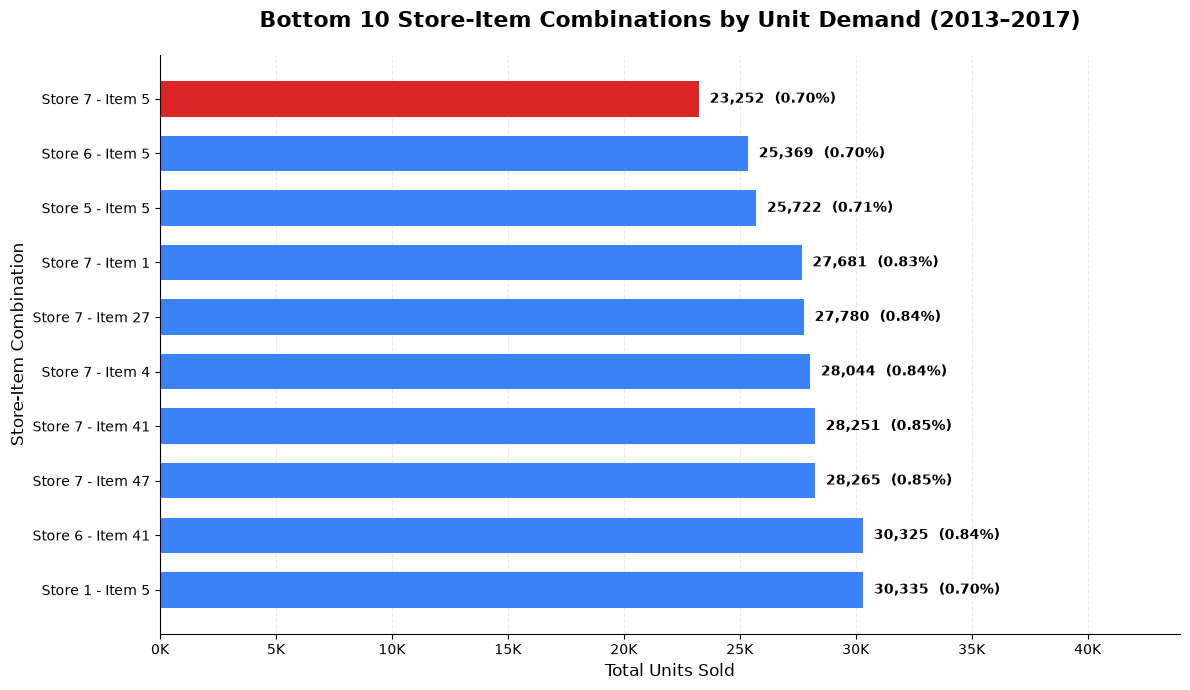

In [64]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Sort so the lowest-demand combination appears at the top
bottom_store_item_chart = (
    bottom_10_store_items
    .sort_values("Total_Units_Sold", ascending=False)
    .copy()
)

# Create readable labels
bottom_store_item_chart["Combination"] = (
    "Store " + bottom_store_item_chart["store"].astype(str)
    + " - Item " + bottom_store_item_chart["item"].astype(str)
)

# Highlight Store 7 - Item 5
colors = [
    "#DC2626" if store == 7 and item == 5 else "#3B82F6"
    for store, item in zip(
        bottom_store_item_chart["store"],
        bottom_store_item_chart["item"]
    )
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    bottom_store_item_chart["Combination"],
    bottom_store_item_chart["Total_Units_Sold"],
    color=colors,
    height=0.65
)

# Add data labels
for bar, (_, row) in zip(bars, bottom_store_item_chart.iterrows()):
    width = bar.get_width()

    ax.text(
        width + 450,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}  "
        f"({row['Store_Sales_Contribution_Percent']:.2f}%)",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Bottom 10 Store-Item Combinations by Unit Demand (2013–2017)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Total Units Sold", fontsize=12)
ax.set_ylabel("Store-Item Combination", fontsize=12)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1000:.0f}K")
)

ax.set_xlim(
    0,
    bottom_store_item_chart["Total_Units_Sold"].max() * 1.45
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [65]:
fig.savefig(
    "../reports/figures/bottom_10_store_item_demand.png",
    dpi=300,
    bbox_inches="tight"
)

print("Bottom 10 Store-Item Demand chart saved successfully!")

Bottom 10 Store-Item Demand chart saved successfully!


### 7.5 Business Insights — Store-Item Demand Analysis

**Observation 1: Store 2 and Item 28 Form the Highest-Demand Combination**

Store 2 – Item 28 recorded the highest historical unit demand at **205,677 units**, averaging **112.64 units per day** between 2013 and 2017.

This combination contributed approximately **3.36%** of Store 2's total unit sales.

Store 2 – Item 15 ranked second with **205,569 units**, only 108 units behind the leading combination.

**Observation 2: Store 7 and Item 5 Form the Lowest-Demand Combination**

Store 7 – Item 5 recorded the lowest historical demand at **23,252 units**, averaging **12.73 units per day**.

This combination contributed approximately **0.70%** of Store 7's total unit sales.

**Observation 3: Store-Level Differences Influence Item Demand**

All Top 10 store-item combinations belong to Stores 2 and 8, with six combinations from Store 2 and four from Store 8.

Meanwhile, six of the Bottom 10 combinations belong to Store 7.

This indicates that demand varies considerably across stores, even when analyzing individual items.

**Observation 4: Certain Items Consistently Appear Among High- or Low-Demand Combinations**

Items 15, 28, 18 and 13 appear among the Top 10 combinations in both Stores 2 and 8.

Item 5 appears in four of the Bottom 10 combinations.

These patterns suggest that both item-level and store-level information may be useful when forecasting demand.

**Observation 5: Large Differences Between Individual Store-Item Combinations**

The highest-demand combination sold approximately **8.85 times** as many units as the lowest-demand combination.

All 500 store-item combinations contain 1,826 daily observations, allowing comparisons across the same historical period.

**Business Implications**

- **Store-Item Forecasting:** Evaluate demand forecasts at the store-item level to capture differences across locations and products.
- **Inventory Allocation:** Consider historical store-item demand when determining replenishment quantities.
- **Demand Segmentation:** Explore whether high- and low-demand combinations require different forecasting approaches.
- **Stock Monitoring:** Investigate inventory requirements for consistently high-demand combinations.
- **Operational Planning:** Use store-item demand patterns to support distribution and replenishment planning.

**Limitations**

The dataset contains historical unit sales but does not include inventory availability, stockout records, selling prices, promotions or profit margins. Consequently, observed sales differences cannot establish their underlying causes or directly determine optimal inventory levels.

**Next Analysis:** Examine demand variability and forecasting-relevant patterns to prepare for time-series modeling.

## 8. Demand Variability Analysis

### 8.1 Overall Daily Demand Variability

**Objective:** Measure fluctuations in overall daily unit demand using descriptive statistics, standard deviation, and the coefficient of variation.

**Analysis Period:** January 2013 – December 2017

**Granularity:** Daily demand aggregated across all 10 stores and 50 items.

In [66]:
# Step 5.9.1 - Overall Daily Demand Variability

import pandas as pd

# Ensure daily sales are in chronological order
daily_demand = (
    daily_sales
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

# Calculate descriptive statistics
mean_demand = daily_demand["Total_Units_Sold"].mean()

median_demand = daily_demand["Total_Units_Sold"].median()

std_demand = daily_demand["Total_Units_Sold"].std()

min_demand = daily_demand["Total_Units_Sold"].min()

max_demand = daily_demand["Total_Units_Sold"].max()

# Calculate demand range
demand_range = max_demand - min_demand

# Calculate coefficient of variation
cv_percent = (std_demand / mean_demand) * 100

# Create summary table
demand_variability = pd.DataFrame({
    "Metric": [
        "Total Calendar Days",
        "Average Daily Demand",
        "Median Daily Demand",
        "Standard Deviation",
        "Minimum Daily Demand",
        "Maximum Daily Demand",
        "Demand Range",
        "Coefficient of Variation (%)"
    ],
    "Value": [
        len(daily_demand),
        mean_demand,
        median_demand,
        std_demand,
        min_demand,
        max_demand,
        demand_range,
        cv_percent
    ]
})

print("========== DAILY DEMAND VARIABILITY ==========")

display(
    demand_variability.style.format({
        "Value": "{:,.2f}"
    })
)

print("========== CALCULATION COMPLETE ==========")

========== DAILY DEMAND VARIABILITY ==========


,Metric,Value
0,Total Calendar Days,"1,826.00"
1,Average Daily Demand,"26,125.14"
2,Median Daily Demand,"25,839.50"
3,Standard Deviation,"6,418.27"
4,Minimum Daily Demand,"11,709.00"
5,Maximum Daily Demand,"44,936.00"
6,Demand Range,"33,227.00"
7,Coefficient of Variation (%),24.57


========== CALCULATION COMPLETE ==========


In [67]:
print("========== DEMAND VARIABILITY VALIDATION ==========")

print("Total Days:", len(daily_demand))

print(
    "Total Units Sold:",
    daily_demand["Total_Units_Sold"].sum()
)

print(
    "Matches Original Dataset:",
    daily_demand["Total_Units_Sold"].sum()
    == df["sales"].sum()
)

print(
    "Missing Values:",
    daily_demand.isnull().sum().sum()
)

print(
    "Duplicate Dates:",
    daily_demand["date"].duplicated().sum()
)

print(
    "Average Daily Demand:",
    round(mean_demand, 2)
)

print(
    "Minimum Daily Demand:",
    min_demand
)

print(
    "Maximum Daily Demand:",
    max_demand
)

print(
    "Standard Deviation:",
    round(std_demand, 2)
)

print(
    "Coefficient of Variation (%):",
    round(cv_percent, 2)
)

print(
    "Demand Range Valid:",
    demand_range == max_demand - min_demand
)

print("========== VALIDATION COMPLETE ==========")

========== DEMAND VARIABILITY VALIDATION ==========
Total Days: 1826
Total Units Sold: 47704512
Matches Original Dataset: True
Missing Values: 0
Duplicate Dates: 0
Average Daily Demand: 26125.14
Minimum Daily Demand: 11709
Maximum Daily Demand: 44936
Standard Deviation: 6418.27
Coefficient of Variation (%): 24.57
Demand Range Valid: True
========== VALIDATION COMPLETE ==========


### 8.2 Daily Demand Rolling Average Analysis

**Objective:** Calculate 7-day and 30-day rolling averages to examine short-term and longer-term changes in daily unit demand.

**Granularity:** Daily demand across all stores and items.

**Note:** Rolling averages are calculated using current and previous observations for descriptive analysis.

In [69]:
# Step 5.9.2 - Daily Demand Rolling Averages

# Create a separate dataframe
rolling_demand = daily_demand.copy()

# Calculate 7-day rolling average
rolling_demand["Rolling_7_Day_Avg"] = (
    rolling_demand["Total_Units_Sold"]
    .rolling(window=7, min_periods=7)
    .mean()
)

# Calculate 30-day rolling average
rolling_demand["Rolling_30_Day_Avg"] = (
    rolling_demand["Total_Units_Sold"]
    .rolling(window=30, min_periods=30)
    .mean()
)

print("========== ROLLING DEMAND SUMMARY ==========")

print("Dataset Shape:", rolling_demand.shape)

print("\nFirst 10 Records:")
display(rolling_demand.head(10))

print("\nLast 10 Records:")
display(rolling_demand.tail(10))

print("========== CALCULATION COMPLETE ==========")

========== ROLLING DEMAND SUMMARY ==========
Dataset Shape: (1826, 4)

First 10 Records:


,date,Total_Units_Sold,Rolling_7_Day_Avg,Rolling_30_Day_Avg
0,2013-01-01,13696,NaN,NaN
1,2013-01-02,13678,NaN,NaN
2,2013-01-03,14488,NaN,NaN
3,2013-01-04,15677,NaN,NaN
4,2013-01-05,16237,NaN,NaN
5,2013-01-06,17291,NaN,NaN
6,2013-01-07,11769,"14,690.86",NaN
7,2013-01-08,13560,"14,671.43",NaN
8,2013-01-09,13878,"14,700.00",NaN
9,2013-01-10,14642,"14,722.00",NaN



Last 10 Records:


,date,Total_Units_Sold,Rolling_7_Day_Avg,Rolling_30_Day_Avg
1816,2017-12-22,23567,"22,244.14","24,567.50"
1817,2017-12-23,24763,"22,217.00","24,361.77"
1818,2017-12-24,26130,"22,211.71","24,145.87"
1819,2017-12-25,17517,"22,179.00","23,565.13"
1820,2017-12-26,20738,"22,210.57","23,023.97"
1821,2017-12-27,20378,"22,186.71","22,889.00"
1822,2017-12-28,21885,"22,139.71","22,658.90"
1823,2017-12-29,23535,"22,135.14","22,486.03"
1824,2017-12-30,24988,"22,167.29","22,291.67"
1825,2017-12-31,26420,"22,208.71","22,390.33"


========== CALCULATION COMPLETE ==========


In [70]:
print("========== ROLLING AVERAGE VALIDATION ==========")

print("Total Days:", len(rolling_demand))

print(
    "Original Sales Preserved:",
    rolling_demand["Total_Units_Sold"].sum()
    == df["sales"].sum()
)

print(
    "7-Day Rolling Missing Values:",
    rolling_demand["Rolling_7_Day_Avg"].isna().sum()
)

print(
    "30-Day Rolling Missing Values:",
    rolling_demand["Rolling_30_Day_Avg"].isna().sum()
)

print(
    "First Valid 7-Day Average Date:",
    rolling_demand.loc[
        rolling_demand["Rolling_7_Day_Avg"].first_valid_index(),
        "date"
    ]
)

print(
    "First Valid 30-Day Average Date:",
    rolling_demand.loc[
        rolling_demand["Rolling_30_Day_Avg"].first_valid_index(),
        "date"
    ]
)

print(
    "Missing Original Sales:",
    rolling_demand["Total_Units_Sold"].isna().sum()
)

print(
    "Duplicate Dates:",
    rolling_demand["date"].duplicated().sum()
)

print("========== VALIDATION COMPLETE ==========")

========== ROLLING AVERAGE VALIDATION ==========
Total Days: 1826
Original Sales Preserved: True
7-Day Rolling Missing Values: 6
30-Day Rolling Missing Values: 29
First Valid 7-Day Average Date: 2013-01-07 00:00:00
First Valid 30-Day Average Date: 2013-01-30 00:00:00
Missing Original Sales: 0
Duplicate Dates: 0
========== VALIDATION COMPLETE ==========


### 8.3 Daily Demand Rolling Average Visualization

**Objective:** Compare actual daily demand with 7-day and 30-day rolling averages to identify short-term fluctuations and longer-term trends.

**Period:** 2013–2017

**Metric:** Total daily units sold across all stores and items.

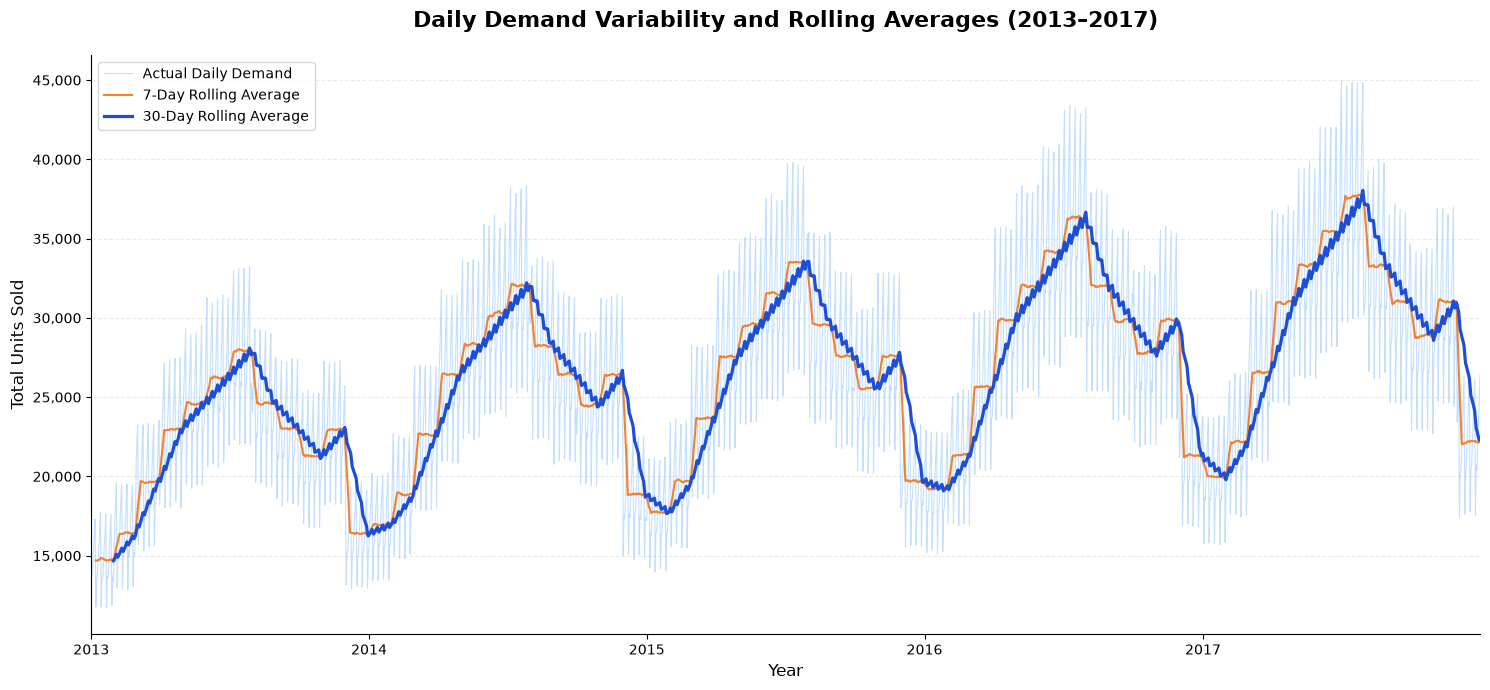

In [71]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(15, 7))

# Actual daily demand
ax.plot(
    rolling_demand["date"],
    rolling_demand["Total_Units_Sold"],
    color="#93C5FD",
    linewidth=0.8,
    alpha=0.55,
    label="Actual Daily Demand"
)

# 7-day rolling average
ax.plot(
    rolling_demand["date"],
    rolling_demand["Rolling_7_Day_Avg"],
    color="#F97316",
    linewidth=1.5,
    alpha=0.9,
    label="7-Day Rolling Average"
)

# 30-day rolling average
ax.plot(
    rolling_demand["date"],
    rolling_demand["Rolling_30_Day_Avg"],
    color="#1D4ED8",
    linewidth=2.3,
    label="30-Day Rolling Average"
)

# Chart title and axis labels
ax.set_title(
    "Daily Demand Variability and Rolling Averages (2013–2017)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total Units Sold", fontsize=12)

# Format X-axis
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.set_xlim(
    rolling_demand["date"].min(),
    rolling_demand["date"].max()
)

# Format Y-axis
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Styling
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.legend(
    loc="upper left",
    fontsize=10,
    frameon=True
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [72]:
from pathlib import Path

output_path = Path(
    "../reports/figures/daily_demand_rolling_averages.png"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print("Chart saved successfully!")
print("Location:", output_path.resolve())

Chart saved successfully!
Location: C:\Users\ANKIT TRIPATHI\Desktop\Sales-Forecasting-Demand-Prediction\reports\figures\daily_demand_rolling_averages.png


### 8.4 Business Insights — Daily Demand Variability and Rolling Averages

**Observation 1: Daily Demand Exhibits Meaningful Variability**

Between 2013 and 2017, average daily demand was approximately **26,125 units**, with a standard deviation of **6,418 units**.

The coefficient of variation was **24.57%**, indicating that daily demand fluctuated noticeably relative to its historical average.

**Observation 2: Historical Demand Shows an Upward Trend**

The 30-day rolling average reveals a generally increasing demand pattern across the five-year period.

Successive annual peaks tend to be higher, consistent with the growth identified in the yearly sales analysis.

**Observation 3: Demand Exhibits Recurring Seasonal Patterns**

The rolling-average visualization shows recurring peaks and troughs across multiple years.

These patterns are consistent with the earlier month-of-year analysis, which identified July as the highest-demand calendar month and January as the lowest.

**Observation 4: Rolling Averages Reveal Different Time Horizons**

The 7-day rolling average reduces daily fluctuations while retaining relatively short-term demand movements.

The 30-day rolling average produces a smoother trend, making broader demand changes and recurring seasonal movements easier to observe.

**Observation 5: Demand Variability Has Forecasting Implications**

Historical demand contains a combination of growth, seasonality, and short-term fluctuations.

Forecasting approaches should therefore be evaluated for their ability to capture these patterns rather than relying only on a constant historical average.

**Business Implications**

- **Demand Forecasting:** Evaluate models that account for historical trends and recurring seasonality.
- **Inventory Planning:** Consider demand fluctuations when estimating future replenishment requirements.
- **Operational Planning:** Anticipate periods of relatively high and low demand when planning operational capacity.
- **Model Evaluation:** Use chronological training and testing periods to assess forecasting performance on unseen future observations.
- **Feature Engineering:** Consider lagged sales and past-only rolling averages as potential forecasting features.

**Limitations**

Rolling averages describe historical sales behavior and do not measure forecasting accuracy.

The rolling averages used in this exploratory analysis include the current day's observed sales. When building predictive features, rolling statistics must use only information available before the prediction date to avoid data leakage.

**Conclusion**

The analysis identifies meaningful historical demand variability alongside recurring seasonal patterns and an upward trend. These findings provide a foundation for developing and evaluating time-series forecasting models.

## 9. Demand Distribution and Outlier Analysis

### 9.1 Daily Demand Distribution Statistics

**Objective:** Analyze the distribution of daily unit demand and identify potential outliers using the Interquartile Range (IQR) method.

**Period:** 2013–2017

**Granularity:** Daily demand aggregated across all stores and items.

In [73]:
# Step 5.10.1 - Demand Distribution Analysis

import pandas as pd

# Reuse validated daily demand data
distribution_data = daily_demand.copy()

sales = distribution_data["Total_Units_Sold"]

# Calculate distribution statistics
mean_sales = sales.mean()
median_sales = sales.median()
std_sales = sales.std()

q1 = sales.quantile(0.25)
q3 = sales.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Identify potential outliers
distribution_data["Is_Outlier"] = (
    (sales < lower_bound) |
    (sales > upper_bound)
)

outlier_count = int(
    distribution_data["Is_Outlier"].sum()
)

outlier_percentage = (
    outlier_count / len(distribution_data)
) * 100

# Create summary table
distribution_summary = pd.DataFrame({
    "Metric": [
        "Total Days",
        "Mean Daily Demand",
        "Median Daily Demand",
        "Standard Deviation",
        "First Quartile (Q1)",
        "Third Quartile (Q3)",
        "Interquartile Range",
        "Lower Outlier Bound",
        "Upper Outlier Bound",
        "Potential Outlier Days",
        "Potential Outlier Percentage"
    ],
    "Value": [
        len(distribution_data),
        mean_sales,
        median_sales,
        std_sales,
        q1,
        q3,
        iqr,
        lower_bound,
        upper_bound,
        outlier_count,
        outlier_percentage
    ]
})

print("========== DEMAND DISTRIBUTION SUMMARY ==========")

display(
    distribution_summary.style.format({
        "Value": "{:,.2f}"
    })
)

print("========== CALCULATION COMPLETE ==========")

========== DEMAND DISTRIBUTION SUMMARY ==========


,Metric,Value
0,Total Days,"1,826.00"
1,Mean Daily Demand,"26,125.14"
2,Median Daily Demand,"25,839.50"
3,Standard Deviation,"6,418.27"
4,First Quartile (Q1),"21,195.00"
5,Third Quartile (Q3),"30,779.50"
6,Interquartile Range,"9,584.50"
7,Lower Outlier Bound,"6,818.25"
8,Upper Outlier Bound,"45,156.25"
9,Potential Outlier Days,0.00


========== CALCULATION COMPLETE ==========


In [74]:
print("========== DEMAND DISTRIBUTION VALIDATION ==========")

print("Total Days:", len(distribution_data))

print(
    "Total Units Sold:",
    distribution_data["Total_Units_Sold"].sum()
)

print(
    "Matches Original Dataset:",
    distribution_data["Total_Units_Sold"].sum()
    == df["sales"].sum()
)

print(
    "Missing Sales Values:",
    distribution_data["Total_Units_Sold"].isna().sum()
)

print(
    "Duplicate Dates:",
    distribution_data["date"].duplicated().sum()
)

print("Mean Daily Demand:", round(mean_sales, 2))
print("Median Daily Demand:", round(median_sales, 2))

print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(iqr, 2))

print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

print("Potential Outlier Days:", outlier_count)

print(
    "Potential Outlier Percentage:",
    round(outlier_percentage, 2)
)

print(
    "Outlier Count Matches:",
    outlier_count ==
    (
        (sales < lower_bound) |
        (sales > upper_bound)
    ).sum()
)

print("========== VALIDATION COMPLETE ==========")

========== DEMAND DISTRIBUTION VALIDATION ==========
Total Days: 1826
Total Units Sold: 47704512
Matches Original Dataset: True
Missing Sales Values: 0
Duplicate Dates: 0
Mean Daily Demand: 26125.14
Median Daily Demand: 25839.5
Q1: 21195.0
Q3: 30779.5
IQR: 9584.5
Lower Bound: 6818.25
Upper Bound: 45156.25
Potential Outlier Days: 0
Potential Outlier Percentage: 0.0
Outlier Count Matches: True
========== VALIDATION COMPLETE ==========


### 9.2 Daily Demand Distribution Visualization

**Objective:** Examine the frequency distribution of daily unit demand and compare the mean and median.

**Period:** 2013–2017

**Granularity:** Daily sales aggregated across all stores and items.

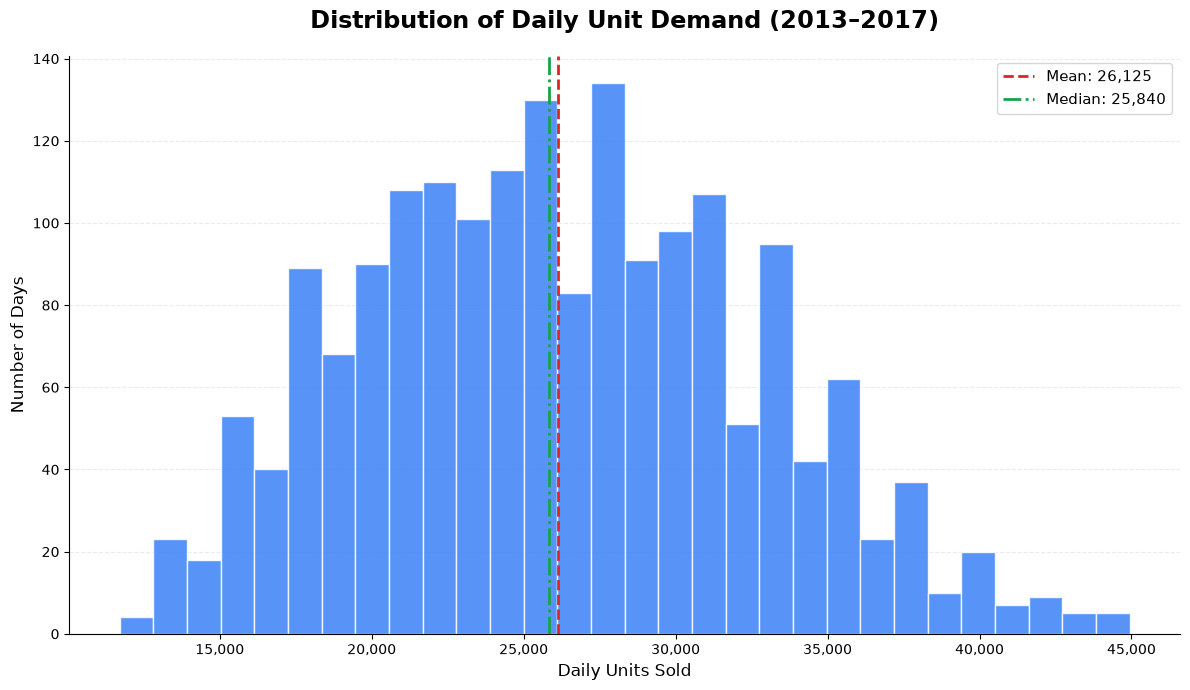

In [75]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 7))

# Create daily demand histogram
ax.hist(
    distribution_data["Total_Units_Sold"],
    bins=30,
    color="#3B82F6",
    edgecolor="white",
    alpha=0.85
)

# Mean reference line
ax.axvline(
    mean_sales,
    color="#DC2626",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_sales:,.0f}"
)

# Median reference line
ax.axvline(
    median_sales,
    color="#16A34A",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_sales:,.0f}"
)

ax.set_title(
    "Distribution of Daily Unit Demand (2013–2017)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Daily Units Sold", fontsize=12)
ax.set_ylabel("Number of Days", fontsize=12)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)
ax.legend(loc="upper right", fontsize=11)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [76]:
from pathlib import Path

output_path = Path(
    "../reports/figures/daily_demand_distribution.png"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print("Daily demand distribution chart saved successfully!")
print("Location:", output_path.resolve())

Daily demand distribution chart saved successfully!
Location: C:\Users\ANKIT TRIPATHI\Desktop\Sales-Forecasting-Demand-Prediction\reports\figures\daily_demand_distribution.png


### 9.3 Daily Demand Box Plot

**Objective:** Visualize the median, interquartile range,
overall spread, and potential outliers in daily unit demand.

**Period:** 2013–2017

**Method:** Standard box plot using the 1.5 × IQR rule.

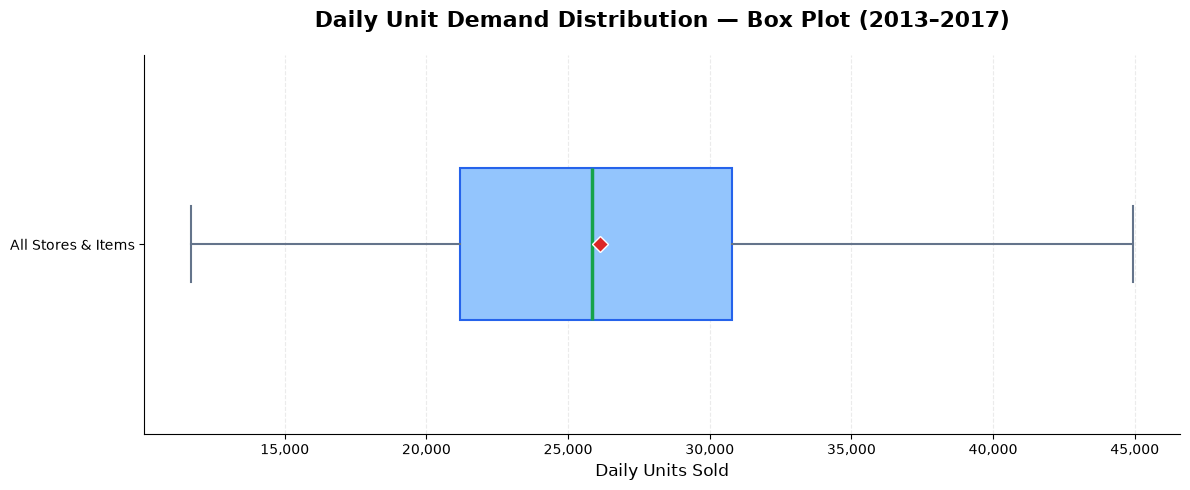

In [78]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 5))

# Create horizontal box plot
box = ax.boxplot(
    distribution_data["Total_Units_Sold"],
    orientation="horizontal",
    patch_artist=True,
    widths=0.4,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#DC2626",
        "markeredgecolor": "white",
        "markersize": 8
    },
    boxprops={
        "facecolor": "#93C5FD",
        "edgecolor": "#2563EB",
        "linewidth": 1.5
    },
    medianprops={
        "color": "#16A34A",
        "linewidth": 2.5
    },
    whiskerprops={
        "color": "#64748B",
        "linewidth": 1.5
    },
    capprops={
        "color": "#64748B",
        "linewidth": 1.5
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "#DC2626",
        "markersize": 5
    }
)

ax.set_title(
    "Daily Unit Demand Distribution — Box Plot (2013–2017)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Daily Units Sold", fontsize=12)
ax.set_yticks([1])
ax.set_yticklabels(["All Stores & Items"])

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [79]:
from pathlib import Path

output_path = Path(
    "../reports/figures/daily_demand_boxplot.png"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print("Daily Demand Box Plot saved successfully!")
print("Location:", output_path.resolve())

Daily Demand Box Plot saved successfully!
Location: C:\Users\ANKIT TRIPATHI\Desktop\Sales-Forecasting-Demand-Prediction\reports\figures\daily_demand_boxplot.png


### 9.4 Business Insights — Demand Distribution and Outlier Analysis

**Observation 1: Daily Demand Is Concentrated Around Its Central Range**

Historical average daily demand was **26,125.14 units**, while the median was **25,839.50 units**.

The relatively small difference between the mean and median suggests that the overall distribution is reasonably balanced around its center, with a slight tendency toward higher demand values.

**Observation 2: The Middle 50% of Daily Demand Falls Within a Defined Range**

The first quartile (Q1) was **21,195 units**, and the third quartile (Q3) was **30,779.50 units**.

This means approximately half of the daily observations fell within this range.

The interquartile range was **9,584.50 units**, indicating meaningful variation in daily demand.

**Observation 3: No Global IQR Outliers Were Identified**

Using the standard 1.5 × IQR method, the lower and upper outlier boundaries were **6,818.25** and **45,156.25 units**, respectively.

All 1,826 daily demand observations fell within these boundaries, resulting in **zero potential outlier days** under this method.

**Observation 4: Demand Still Exhibits Considerable Variation**

The lowest observed daily demand was **11,709 units**, while the highest was **44,936 units**.

The absence of global IQR outliers does not imply that demand is constant or that unusual local demand changes are absent.

**Observation 5: Historical Trends and Seasonality Influence the Distribution**

The distribution combines observations across five years of growth and recurring seasonal patterns.

Consequently, unusually high or low demand relative to a particular month, store, or item may not be identified by a single global IQR threshold.

**Business Implications**

- **Demand Forecasting:** Evaluate forecasting methods that account for trend, seasonality, and demand fluctuations.
- **Inventory Planning:** Use historical demand ranges as context when planning inventory requirements.
- **Anomaly Detection:** Consider time-aware and store-item-specific methods for identifying unusual demand changes.
- **Data Quality:** Avoid automatically deleting high- or low-demand observations without investigating their business context.
- **Operational Planning:** Recognize that demand can vary substantially even when no global statistical outliers are present.

**Limitations**

The IQR method identifies potential statistical outliers, not confirmed data errors.

Global outlier detection may overlook unusual observations within individual stores, items, or seasonal periods.

The dataset also lacks inventory availability, promotional activity, and other external factors that could help explain unexpected demand changes.

**Conclusion**

Daily unit demand is concentrated around approximately 26,000 units but exhibits substantial variation. No global IQR outliers were identified. Further forecasting analysis should account for historical trends, seasonality, and differences between store-item combinations.

## 10. Time Series Decomposition Analysis

### 10.1 Daily Time Series Preparation

**Objective:** Prepare and validate the daily unit demand
series for time series decomposition.

**Analysis Period:** January 2013 – December 2017

**Granularity:** Daily demand across all stores and items.

**Initial Seasonal Period:** 7 days (weekly seasonality).

**Method:** Additive decomposition, to be performed
after time series validation.

In [80]:
# Step 5.11.1 - Prepare Daily Time Series

import pandas as pd

# Reuse previously validated daily sales
ts_data = daily_sales.copy()

# Ensure date is datetime
ts_data["date"] = pd.to_datetime(ts_data["date"])

# Sort by date
ts_data = ts_data.sort_values("date")

# Set date as index
ts_data = ts_data.set_index("date")

# Ensure daily frequency
ts_data = ts_data.asfreq("D")

# Select demand series
ts_demand = ts_data["Total_Units_Sold"]

print("========== TIME SERIES PREPARATION ==========")

print("Time Series Shape:", ts_demand.shape)

print("Index Type:", type(ts_demand.index))

print("Frequency:", ts_demand.index.freqstr)

print("\nFirst 5 Records:")
display(ts_demand.head())

print("\nLast 5 Records:")
display(ts_demand.tail())

print("========== PREPARATION COMPLETE ==========")

========== TIME SERIES PREPARATION ==========
Time Series Shape: (1826,)
Index Type: <class 'pandas.DatetimeIndex'>
Frequency: D

First 5 Records:


date
2013-01-01    13696
2013-01-02    13678
2013-01-03    14488
2013-01-04    15677
2013-01-05    16237
Freq: D, Name: Total_Units_Sold, dtype: int64


Last 5 Records:


date
2017-12-27    20378
2017-12-28    21885
2017-12-29    23535
2017-12-30    24988
2017-12-31    26420
Freq: D, Name: Total_Units_Sold, dtype: int64

========== PREPARATION COMPLETE ==========


In [81]:
# Step 5.11.1 - Time Series Validation

print("========== TIME SERIES VALIDATION ==========")

print("Total Days:", len(ts_demand))

print("First Date:", ts_demand.index.min())

print("Last Date:", ts_demand.index.max())

print("Frequency:", ts_demand.index.freqstr)

print("Missing Values:", ts_demand.isna().sum())

print("Duplicate Dates:", ts_demand.index.duplicated().sum())

print("Index Sorted:", ts_demand.index.is_monotonic_increasing)

print("Total Units Sold:", ts_demand.sum())

print(
    "Matches Original Dataset:",
    ts_demand.sum() == df["sales"].sum()
)

print(
    "Expected Calendar Days:",
    len(
        pd.date_range(
            ts_demand.index.min(),
            ts_demand.index.max(),
            freq="D"
        )
    )
)

print("========== VALIDATION COMPLETE ==========")

========== TIME SERIES VALIDATION ==========
Total Days: 1826
First Date: 2013-01-01 00:00:00
Last Date: 2017-12-31 00:00:00
Frequency: D
Missing Values: 0
Duplicate Dates: 0
Index Sorted: True
Total Units Sold: 47704512
Matches Original Dataset: True
Expected Calendar Days: 1826
========== VALIDATION COMPLETE ==========


### 10.2 Weekly Seasonal Decomposition

**Objective:** Decompose daily unit demand into trend,
weekly seasonal, and residual components.

**Method:** Additive seasonal decomposition.

**Seasonal Period:** 7 days.

**Analysis Period:** January 2013 – December 2017.

**Note:** This is a retrospective exploratory analysis,
not a forecasting model.

In [82]:
import statsmodels

print("Statsmodels Version:", statsmodels.__version__)
print("Statsmodels imported successfully!")

Statsmodels Version: 0.15.0
Statsmodels imported successfully!


In [83]:
# Step 5.11.2 - Weekly Seasonal Decomposition

import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform additive decomposition
decomposition = seasonal_decompose(
    ts_demand,
    model="additive",
    period=7,
    extrapolate_trend=0
)

# Extract components
trend_component = decomposition.trend
seasonal_component = decomposition.seasonal
residual_component = decomposition.resid

# Create decomposition dataframe
decomposition_df = pd.DataFrame({
    "Observed": ts_demand,
    "Trend": trend_component,
    "Seasonal": seasonal_component,
    "Residual": residual_component
})

print("========== WEEKLY DECOMPOSITION SUMMARY ==========")
print("Dataset Shape:", decomposition_df.shape)

print("\nFirst 10 Records:")
display(decomposition_df.head(10))

print("\nLast 10 Records:")
display(decomposition_df.tail(10))

print("========== DECOMPOSITION COMPLETE ==========")

========== WEEKLY DECOMPOSITION SUMMARY ==========
Dataset Shape: (1826, 4)

First 10 Records:


,Observed,Trend,Seasonal,Residual
date,,,,
2013-01-01,13696,NaN,"-1,997.80",NaN
2013-01-02,13678,NaN,"-1,930.96",NaN
2013-01-03,14488,NaN,-255.29,NaN
2013-01-04,15677,"14,690.86","1,459.29",-473.15
2013-01-05,16237,"14,671.43","3,209.30","-1,643.73"
2013-01-06,17291,"14,700.00","4,947.12","-2,356.12"
2013-01-07,11769,"14,722.00","-5,431.68","2,478.68"
2013-01-08,13560,"14,715.71","-1,997.80",842.08
2013-01-09,13878,"14,778.86","-1,930.96","1,030.10"



Last 10 Records:


,Observed,Trend,Seasonal,Residual
date,,,,
2017-12-22,23567,"22,179.00","1,459.29",-71.29
2017-12-23,24763,"22,210.57","3,209.30",-656.87
2017-12-24,26130,"22,186.71","4,947.12","-1,003.84"
2017-12-25,17517,"22,139.71","-5,431.68",808.96
2017-12-26,20738,"22,135.14","-1,997.80",600.65
2017-12-27,20378,"22,167.29","-1,930.96",141.68
2017-12-28,21885,"22,208.71",-255.29,-68.43
2017-12-29,23535,NaN,"1,459.29",NaN
2017-12-30,24988,NaN,"3,209.30",NaN


========== DECOMPOSITION COMPLETE ==========


In [84]:
# Step 5.11.2 - Weekly Decomposition Validation

print("========== WEEKLY DECOMPOSITION VALIDATION ==========")

print("Total Days:", len(decomposition_df))

print(
    "Observed Sales Preserved:",
    decomposition_df["Observed"].sum() == df["sales"].sum()
)

print(
    "Missing Observed Values:",
    decomposition_df["Observed"].isna().sum()
)

print(
    "Missing Trend Values:",
    decomposition_df["Trend"].isna().sum()
)

print(
    "Missing Seasonal Values:",
    decomposition_df["Seasonal"].isna().sum()
)

print(
    "Missing Residual Values:",
    decomposition_df["Residual"].isna().sum()
)

# Reconstruct original demand
valid_rows = decomposition_df.dropna()

reconstructed = (
    valid_rows["Trend"]
    + valid_rows["Seasonal"]
    + valid_rows["Residual"]
)

max_reconstruction_error = (
    valid_rows["Observed"] - reconstructed
).abs().max()

print(
    "Maximum Reconstruction Error:",
    round(max_reconstruction_error, 10)
)

print(
    "Reconstruction Valid:",
    max_reconstruction_error < 1e-6
)

print(
    "Average Weekly Seasonal Effect:",
    round(seasonal_component.mean(), 6)
)

print("========== VALIDATION COMPLETE ==========")

========== WEEKLY DECOMPOSITION VALIDATION ==========
Total Days: 1826
Observed Sales Preserved: True
Missing Observed Values: 0
Missing Trend Values: 6
Missing Seasonal Values: 0
Missing Residual Values: 6
Maximum Reconstruction Error: 0.0
Reconstruction Valid: True
Average Weekly Seasonal Effect: 2.974632
========== VALIDATION COMPLETE ==========


### 10.3 Weekly Seasonal Decomposition Visualization

**Objective:** Visualize observed daily demand, estimated trend,
weekly seasonality, and residual fluctuations.

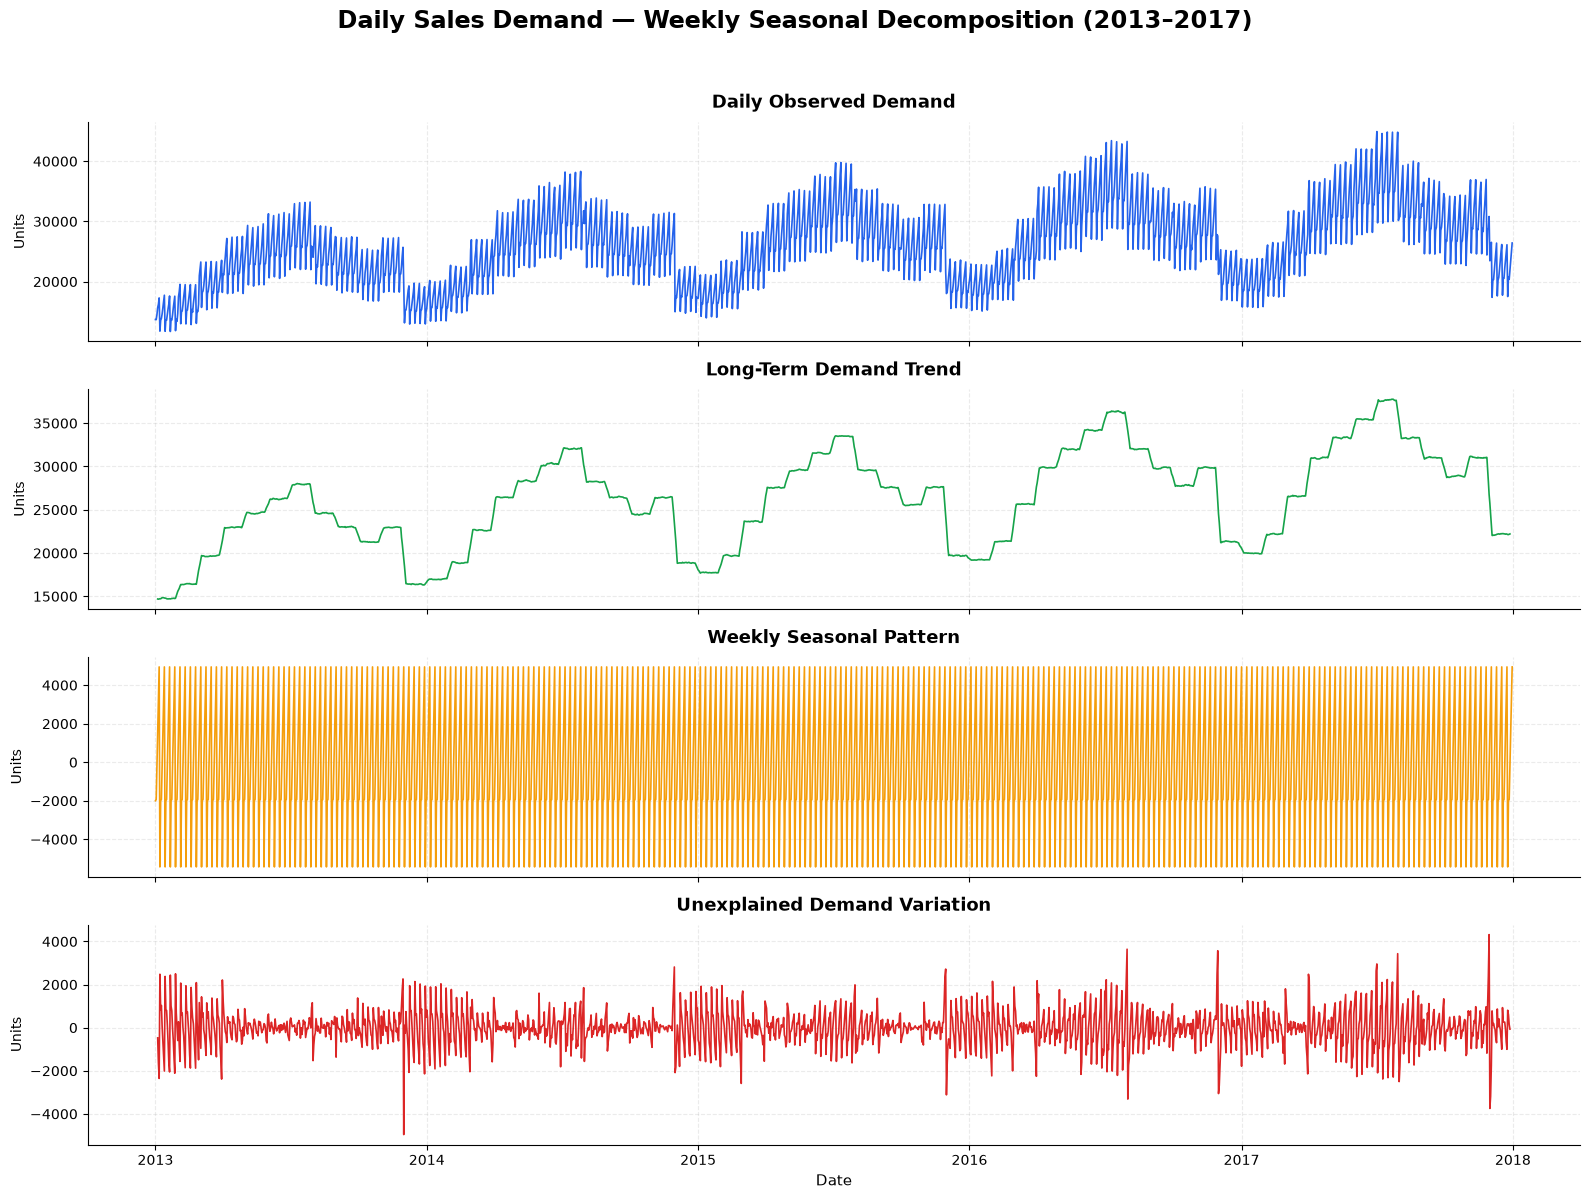

Chart saved to: C:\Users\ANKIT TRIPATHI\Desktop\Sales-Forecasting-Demand-Prediction\reports\figures\weekly_seasonal_decomposition.png


In [85]:
# Step 5.11.3 - Weekly Seasonal Decomposition Visualization

import matplotlib.pyplot as plt
from pathlib import Path

# Create output directory
output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Create four vertically aligned charts
fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(16, 12),
    sharex=True
)

components = [
    ("Observed", "Daily Observed Demand", "#2563EB"),
    ("Trend", "Long-Term Demand Trend", "#16A34A"),
    ("Seasonal", "Weekly Seasonal Pattern", "#F59E0B"),
    ("Residual", "Unexplained Demand Variation", "#DC2626")
]

for ax, (column, title, color) in zip(axes, components):

    ax.plot(
        decomposition_df.index,
        decomposition_df[column],
        color=color,
        linewidth=1.2
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=10
    )

    ax.set_ylabel("Units", fontsize=10)

    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel("Date", fontsize=11)

fig.suptitle(
    "Daily Sales Demand — Weekly Seasonal Decomposition (2013–2017)",
    fontsize=17,
    fontweight="bold",
    y=0.995
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

# Save chart
chart_path = output_dir / "weekly_seasonal_decomposition.png"

fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to:", chart_path.resolve())

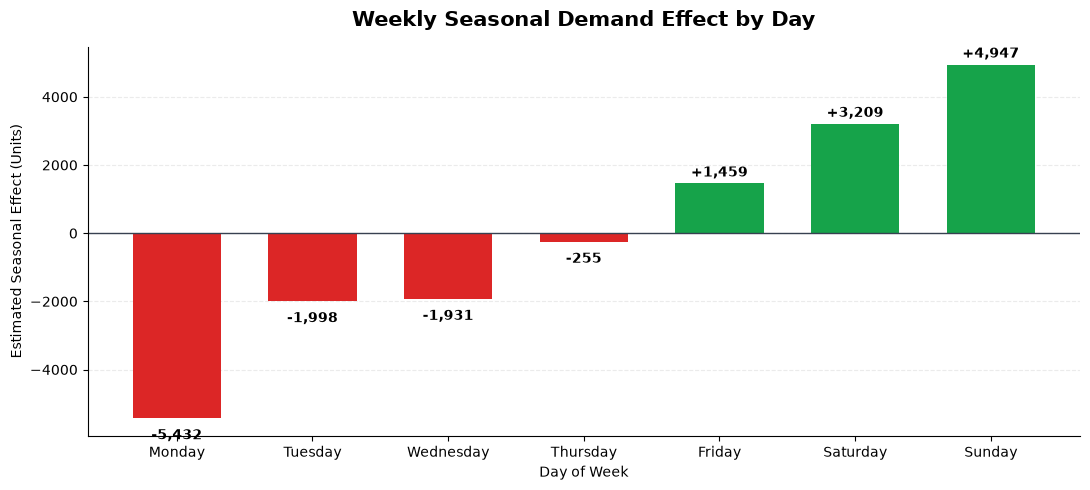

Chart saved to: C:\Users\ANKIT TRIPATHI\Desktop\Sales-Forecasting-Demand-Prediction\reports\figures\weekly_seasonal_profile.png

Weekly Seasonal Effects:
date
0   -5,431.68
1   -1,997.80
2   -1,930.96
3     -255.29
4    1,459.29
5    3,209.30
6    4,947.12
Name: seasonal, dtype: float64

Sum of Seven Seasonal Effects: -0.0


In [87]:
# Step 5.11.3 - Weekly Seasonal Profile

import matplotlib.pyplot as plt

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_profile = (
    seasonal_component
    .groupby(seasonal_component.index.day_of_week)
    .mean()
    .reindex(range(7))
)

fig, ax = plt.subplots(figsize=(11, 5))

colors = [
    "#DC2626" if value < 0 else "#16A34A"
    for value in weekly_profile
]

bars = ax.bar(
    weekday_names,
    weekly_profile.values,
    color=colors,
    width=0.65
)

ax.axhline(0, color="#374151", linewidth=1)

for bar, value in zip(bars, weekly_profile.values):
    ax.annotate(
        f"{value:+,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5 if value >= 0 else -15),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Weekly Seasonal Demand Effect by Day",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Estimated Seasonal Effect (Units)")
ax.set_xlabel("Day of Week")

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

chart_path = output_dir / "weekly_seasonal_profile.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to:", chart_path.resolve())
print("\nWeekly Seasonal Effects:")
print(weekly_profile.round(2))
print("\nSum of Seven Seasonal Effects:",
      round(weekly_profile.sum(), 6))

### 10.4 Business Insights — Weekly Seasonal Decomposition

**Objective:** Identify recurring weekly demand patterns and understand their implications for sales forecasting and inventory planning.

#### Key Findings

1. **Strong Weekly Seasonality:** The decomposition reveals a consistent seven-day demand cycle across the historical dataset.

2. **Sunday Has the Highest Positive Seasonal Effect:** Sunday contributes approximately **+4,947 units** relative to the estimated trend, making it the strongest day in the weekly seasonal pattern.

3. **Monday Has the Lowest Seasonal Effect:** Monday shows approximately **−5,432 units** relative to the estimated trend, indicating substantially weaker demand compared with other weekdays.

4. **Weekend Demand Is Stronger:** Saturday (+3,209 units) and Sunday (+4,947 units) have the largest positive seasonal effects, consistent with the earlier weekday/weekend demand analysis.

5. **Demand Also Shows Longer-Term Variation:** The trend component displays changes across multiple years, including recurring annual peaks and declines. The seven-day decomposition does not separately isolate annual seasonality.

6. **Residual Fluctuations Remain:** The residual component contains unexplained variations and occasional spikes, indicating that weekly seasonality and the estimated trend do not explain every daily demand movement.

#### Business Implications

- **Inventory Planning:** Businesses can prepare additional inventory ahead of historically stronger weekend demand.
- **Workforce Scheduling:** Staffing and operational capacity can be aligned with expected daily demand patterns.
- **Demand Forecasting:** Day-of-week indicators and historical lag features are potential predictors for future forecasting models.
- **Operational Efficiency:** Understanding low-demand and high-demand days can support more effective replenishment and resource allocation.

#### Analytical Limitations

This analysis uses aggregate daily unit sales across all stores and items. Individual stores and products may have different weekly patterns.

The decomposition is retrospective and uses the complete historical dataset. Its full-series components must not be used directly as features in a forecasting evaluation because that would introduce future-information leakage.

**Conclusion:** Weekly seasonality is an important characteristic of the dataset and should be considered when developing and evaluating future demand forecasting models.